In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
h1 = ['labor_force',
      'inflation',
      'gov_exp',
      'govermment_effective',
      'gdp',
      'unemployment',
     ]

### Import the data
* Import data that describe countries in one point

In [3]:
one_point_countries_win6 = pd.read_parquet('../data/one_point_countries_winsorized.parquet')

In [4]:
one_point_countries_win6.shape

(53, 189)

In [5]:
def filter_macro_columns_with_country(df, macro_keywords, keep_column="Country"):
    """
    Conserva solo las columnas del DataFrame que contienen alguna palabra clave en 'macro_keywords',
    además de la columna 'Country'.

    Parámetros:
    - df: pandas.DataFrame
        El DataFrame original con muchas columnas macroeconómicas.
    - macro_keywords: list of str
        Lista de palabras clave que deben estar presentes en el nombre de las columnas a conservar.
    - keep_column: str
        Columna adicional que se desea conservar (por defecto 'Country').

    Retorna:
    - df_filtrado: pandas.DataFrame
        DataFrame con solo las columnas relevantes.
    """

    columnas_filtradas = [
        col for col in df.columns
        if any(keyword in col for keyword in macro_keywords)
    ]

    # Asegurar que 'Country' esté incluido si existe en el DataFrame
    if keep_column in df.columns and keep_column not in columnas_filtradas:
        columnas_filtradas.insert(0, keep_column)

    df_filtrado = df[columnas_filtradas].copy()

    print(f"Columnas conservadas ({len(columnas_filtradas)}): {columnas_filtradas}")
    return df_filtrado

In [6]:
countries_win6_h1 = filter_macro_columns_with_country(one_point_countries_win6, h1)

Columnas conservadas (67): ['Country', 'labor_force_mean', 'labor_force_median', 'labor_force_std', 'labor_force_min', 'labor_force_max', 'labor_force_last', 'gov_exp_mean', 'gov_exp_median', 'gov_exp_std', 'gov_exp_cv', 'gov_exp_min', 'gov_exp_max', 'gov_exp_last', 'gov_exp_growth', 'gov_exp_trend', 'gdp_mean', 'gdp_median', 'gdp_std', 'gdp_cv', 'gdp_min', 'gdp_max', 'gdp_last', 'gdp_growth', 'gdp_trend', 'unemployment_mean', 'unemployment_median', 'unemployment_std', 'unemployment_min', 'unemployment_max', 'unemployment_last', 'inflation__mean', 'inflation__median', 'inflation__std', 'inflation__cv', 'inflation__max', 'inflation__last', 'govermment_effective__std', 'labor_force_cv', 'labor_force_growth', 'labor_force_skew', 'labor_force_kurtosis', 'labor_force_trend', 'gov_exp_skew', 'gov_exp_kurtosis', 'gdp_skew', 'gdp_kurtosis', 'unemployment_cv', 'unemployment_growth', 'unemployment_skew', 'unemployment_kurtosis', 'unemployment_trend', 'inflation__min', 'inflation__growth', 'infla

In [7]:
countries_win6_h1.shape

(53, 67)

### Delete countries that represent most outliers in house price index

In [8]:
def remove_rows_by_countries(df, country_list, column="Country"):
    """
    Removes rows from the DataFrame where the value in the specified column matches any country in the list.
    Prints a message if any country in the list is not found.

    Parameters:
    - df: Original DataFrame.
    - country_list: List of country names to remove.
    - column: Name of the column containing country names (default is 'Country').

    Returns:
    - DataFrame without the rows corresponding to those countries.
    """
    df = df.copy()
    existing_countries = set(df[column].dropna().astype(str).unique())
    not_found = [country for country in country_list if country not in existing_countries]

    if not_found:
        print(f"⚠️ The following countries were not found in column '{column}': {not_found}")

    return df[~df[column].isin(country_list)].copy()

In [9]:
delete_countries = ["Hong-Kong","India","Turkey"]

In [10]:
countries_win6_h1 = remove_rows_by_countries(countries_win6_h1, delete_countries)

⚠️ The following countries were not found in column 'Country': ['Hong-Kong']


In [11]:
countries_win6_h1.reset_index(inplace=True)

### Apply PCA

In [12]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

In [13]:
pca_input_h1 = countries_win6_h1.select_dtypes(include='number')

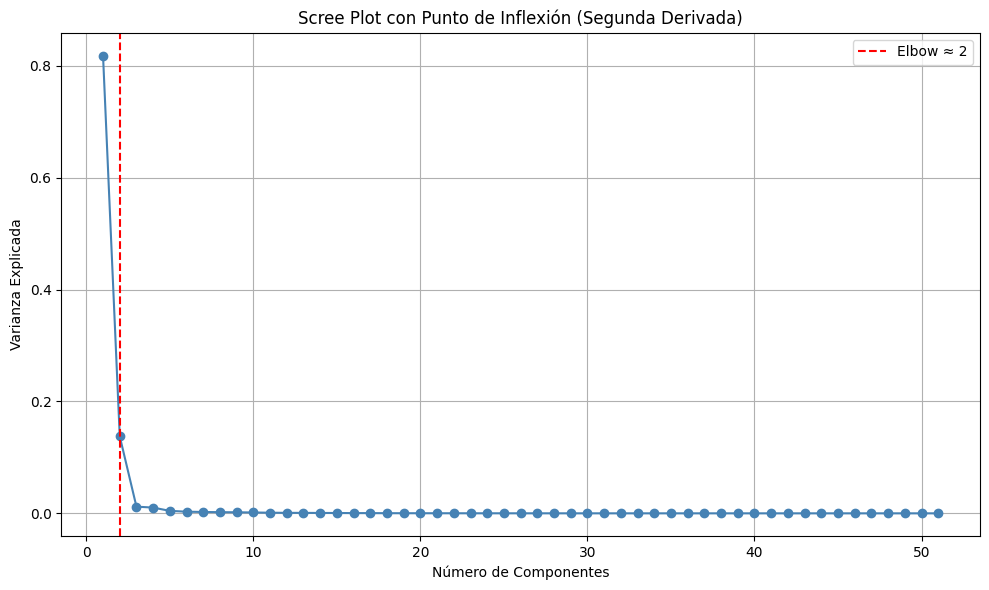

Punto de inflexión sugerido por segunda derivada: 2


In [14]:
# PCA completo
pca_full = PCA()
pca_full.fit(pca_input_h1)

# Varianza explicada
explained_var = pca_full.explained_variance_ratio_

# Segunda derivada
second_derivative = np.diff(explained_var, n=2)
elbow_point = np.argmax(second_derivative) + 2  # +2 para alinear con el número de componentes

# Plot
plt.figure(figsize=(10, 6))
plt.plot(range(1, len(explained_var) + 1), explained_var, marker='o', linestyle='-', color='steelblue')
plt.axvline(x=elbow_point, color='red', linestyle='--', label=f'Elbow ≈ {elbow_point}')
plt.xlabel('Número de Componentes')
plt.ylabel('Varianza Explicada')
plt.title('Scree Plot con Punto de Inflexión (Segunda Derivada)')
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

# Imprimir punto de inflexión
print(f"Punto de inflexión sugerido por segunda derivada: {elbow_point}")

In [15]:
#scaler = StandardScaler()
#pca_input_scaled = scaler.fit_transform(pca_input)

In [16]:
pca_2_h1 = PCA(n_components=2)

In [17]:
countries_win6_h1_pca2 = pca_2_h1.fit_transform(pca_input_h1)

In [18]:
pca_df_h1_2 = pd.DataFrame(countries_win6_h1_pca2, columns=['PC1', 'PC2'])

In [19]:
print(pca_2_h1.explained_variance_ratio_)
print(pca_2_h1.explained_variance_ratio_.sum())

[0.81819568 0.13774793]
0.9559436019191163


### Develop Cluster KMeans++
* With elbow method
* With silhouette plot for quality
* Export df with country, iso_a3, cluster category and continent in parquet format, manage missing values before importing

In [20]:
from sklearn.cluster import KMeans

In [21]:
pca_df_h1_2.shape

(51, 2)

#### Using the elbow method to find the optimal number of clusters

In [22]:
import time

In [23]:
distortions = []
# Parameters
n_init_list = [10, 20]
max_iter_list = [100, 500]
n_clusters_range = range(1, 11)
random_states = [21, 42]


Running elbow plots for random_state=21


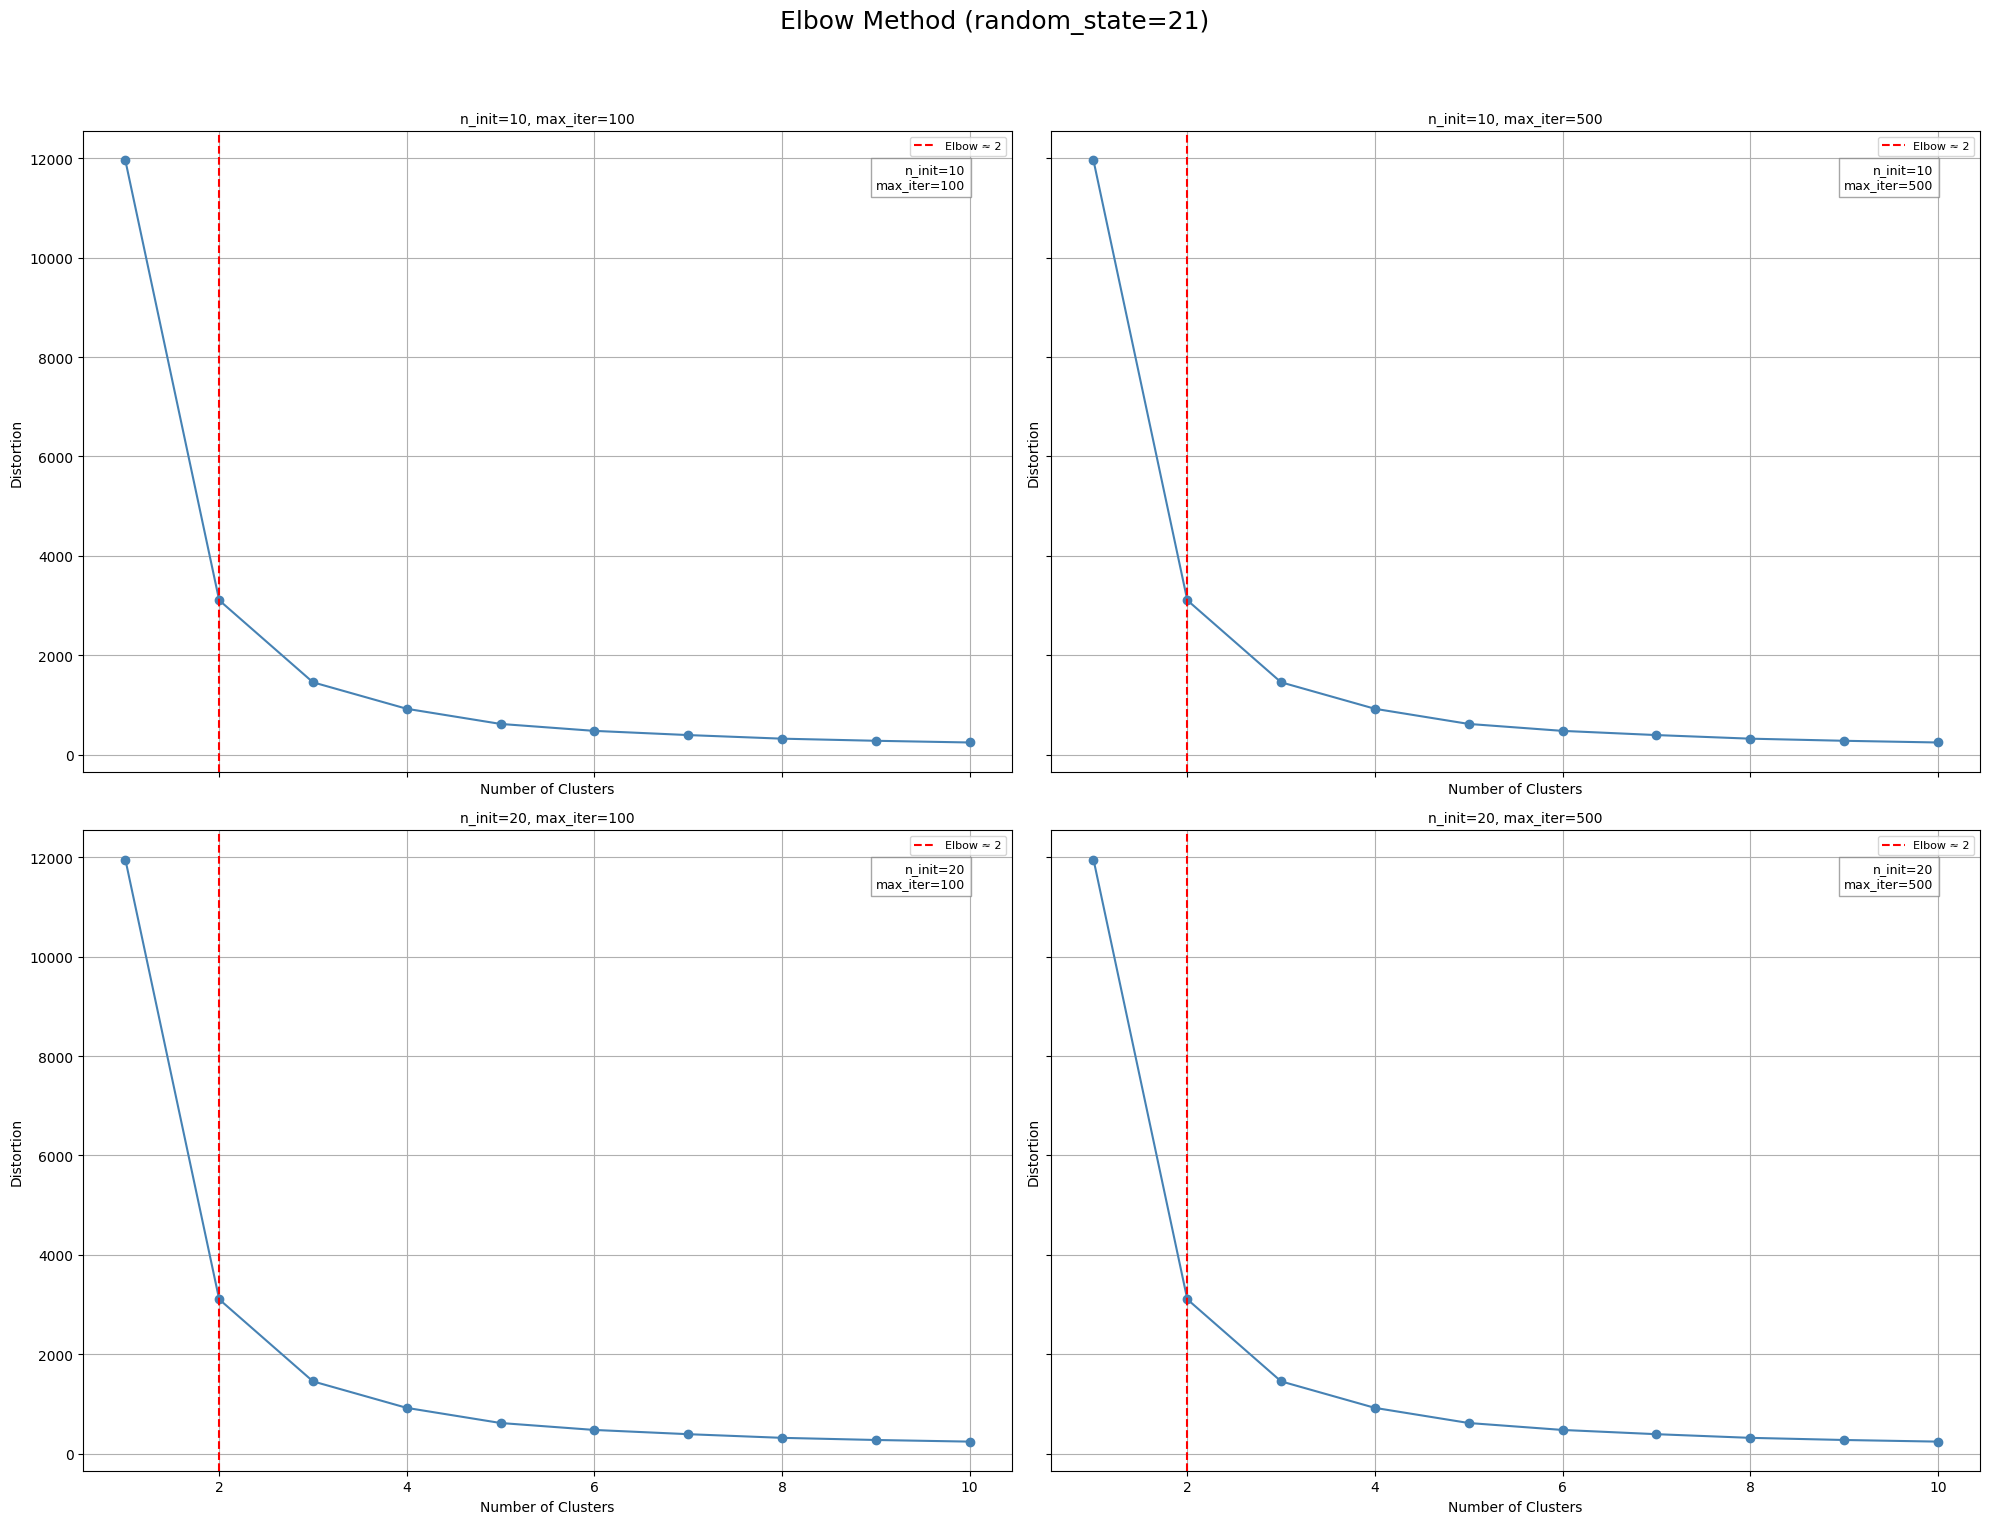


Running elbow plots for random_state=42


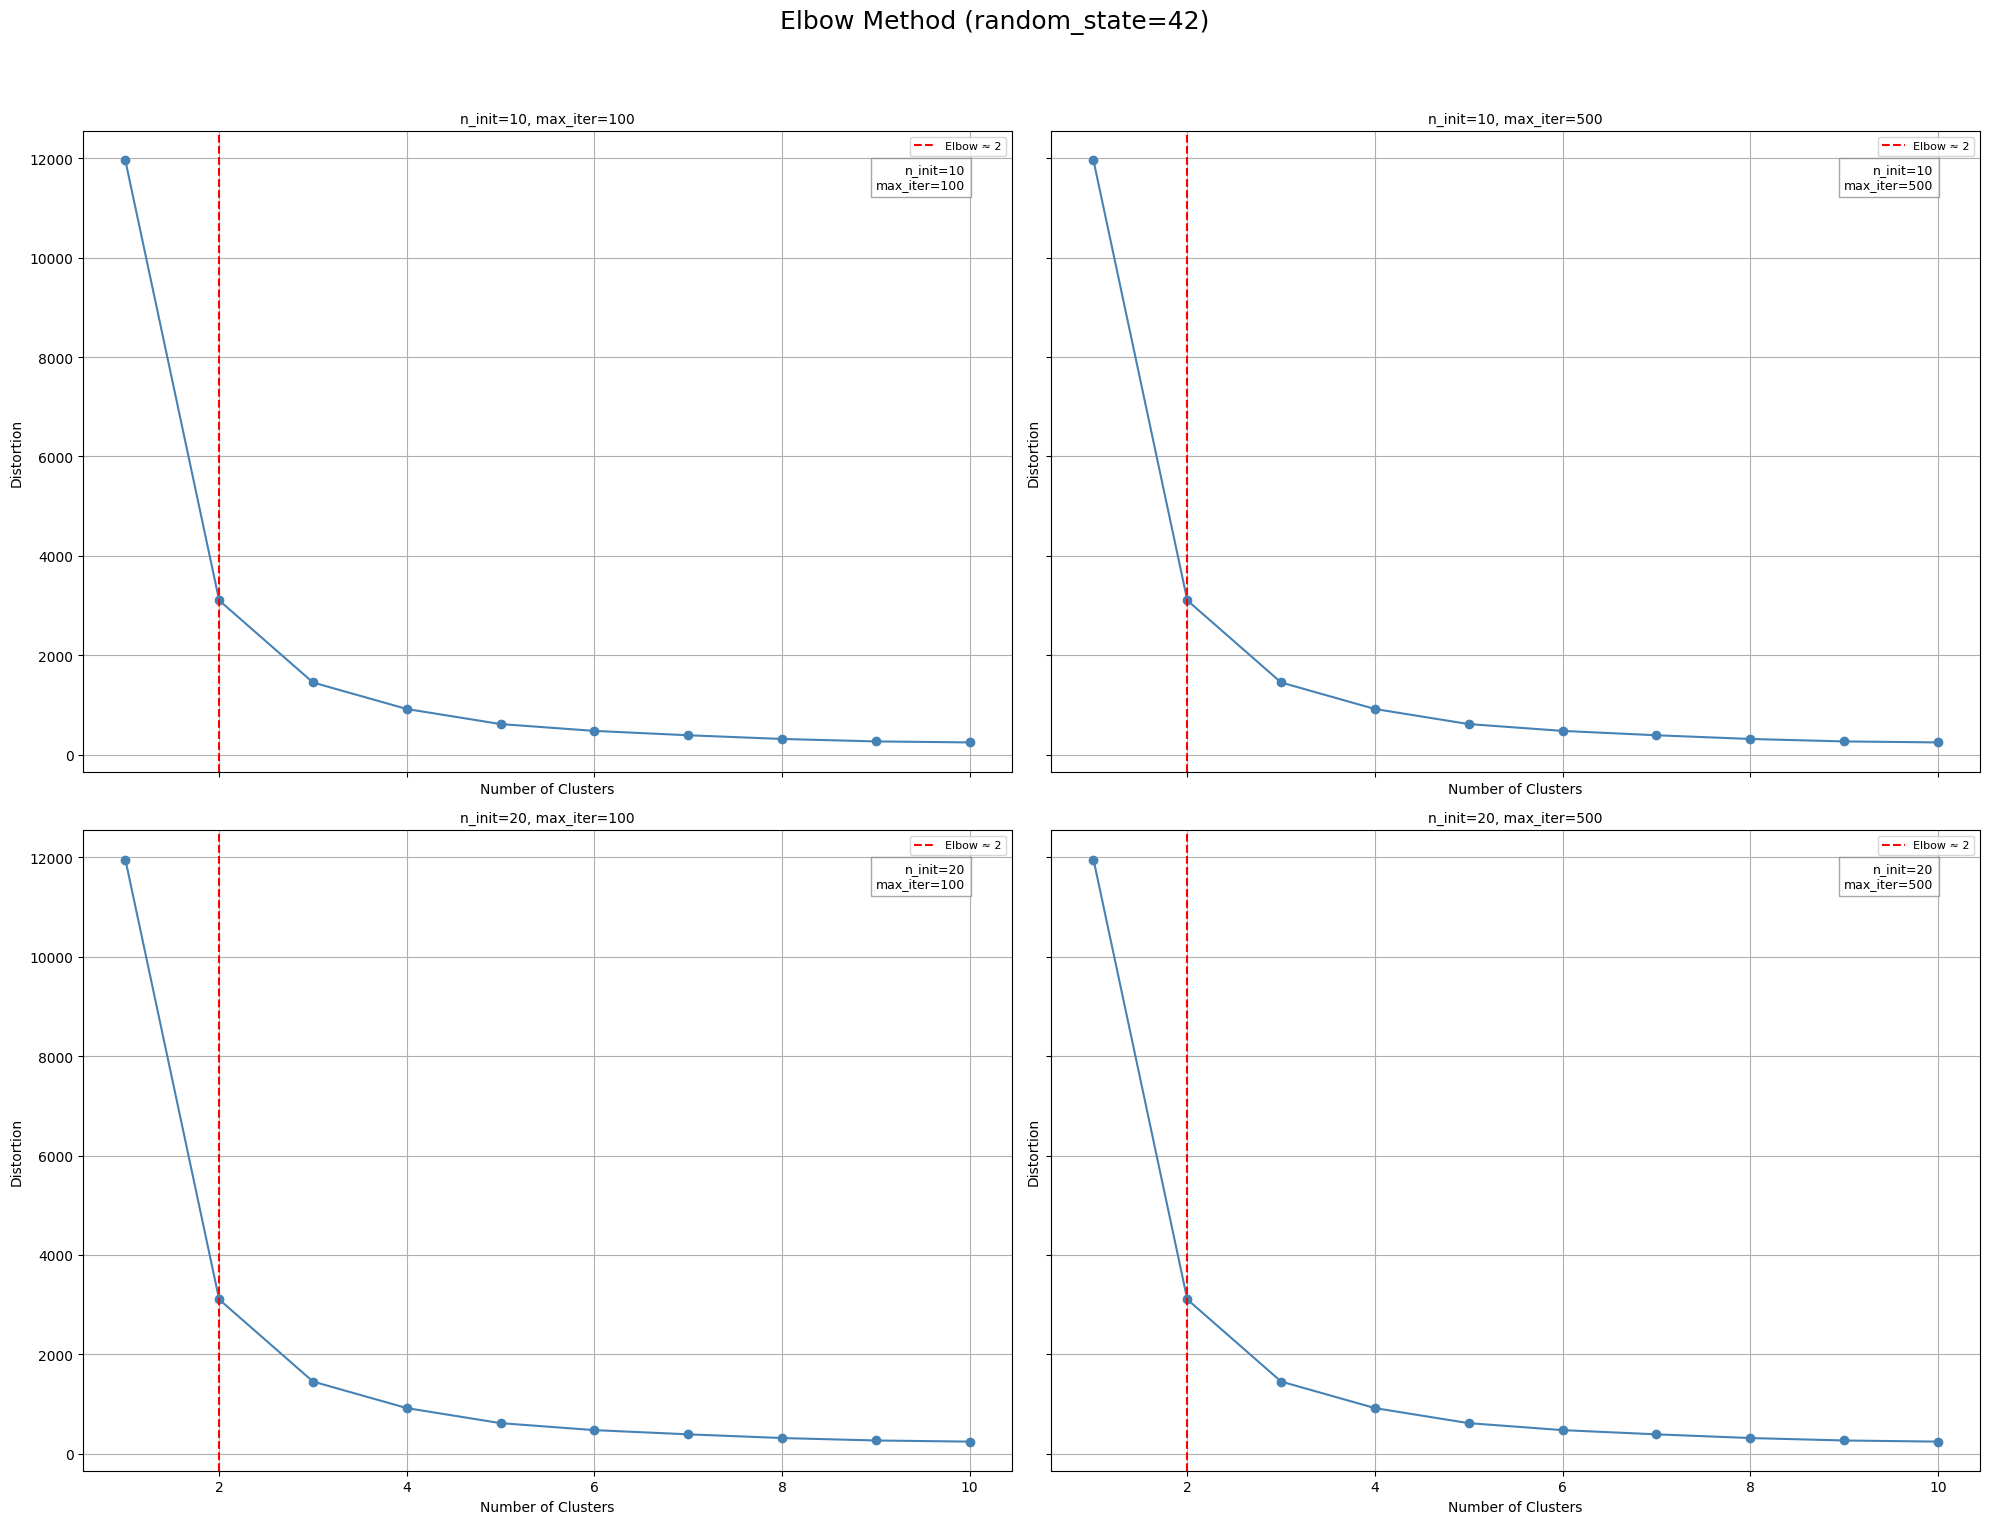


Total execution time: 7.35 seconds


In [23]:
# Start timer
start_time = time.time()

# Iterate over random states
for rs in random_states:
    print(f"\nRunning elbow plots for random_state={rs}")

    # Create figure grid
    fig, axes = plt.subplots(len(n_init_list), len(max_iter_list), figsize=(20, 16), sharex=True, sharey=True)
    fig.suptitle(f'Elbow Method (random_state={rs})', fontsize=18)

    # Iterate over parameter combinations
    for i, n_init in enumerate(n_init_list):
        for j, max_iter in enumerate(max_iter_list):
            distortions = []
            for k in n_clusters_range:
                km = KMeans(
                    n_clusters=k,
                    init='k-means++',
                    n_init=n_init,
                    max_iter=max_iter,
                    random_state=rs
                )
                km.fit(pca_df_h1_2)
                distortions.append(km.inertia_)

            # Compute second derivative to find elbow
            second_derivative = np.diff(distortions, n=2)
            elbow_point = np.argmax(second_derivative) + 2  # +2 to align with cluster count

            # Plot
            ax = axes[i, j]
            ax.plot(n_clusters_range, distortions, marker='o', linestyle='-', color='steelblue')
            ax.axvline(x=elbow_point, color='red', linestyle='--', label=f'Elbow ≈ {elbow_point}')
            ax.set_title(f'n_init={n_init}, max_iter={max_iter}', fontsize=10)
            ax.set_xlabel('Number of Clusters')
            ax.set_ylabel('Distortion')
            ax.grid(True)
            ax.legend(loc='upper right', fontsize=8)

            # Annotate parameters inside plot
            ax.text(
                0.95, 0.95,
                f'n_init={n_init}\nmax_iter={max_iter}',
                transform=ax.transAxes,
                fontsize=9,
                verticalalignment='top',
                horizontalalignment='right',
                bbox=dict(facecolor='white', alpha=0.7, edgecolor='gray')
            )

    # Final layout and display
    plt.tight_layout(rect=[0, 0.03, 1, 0.95])
    plt.show()

# End timer
end_time = time.time()
print(f"\nTotal execution time: {end_time - start_time:.2f} seconds")

#### Quantifying the quality of clustering via silhouette plots

The previous code was a nonsense since each iteration found the same elbow, so we will see if each iteration with a different hyperparameter results in a cluster with different members.

The code for each model will be as follows:
- cx = where c corresponds to 'clusters' and x corresponds to the number of clusters used
- nix = where ni corresponds to 'n_init' and x to the number of initializations used
- maxix = where maxi corresponds to 'max_iter' and x to the number of maximum iterations selected

In [24]:
from sklearn.metrics import silhouette_samples
from matplotlib import cm

In [25]:
def plot_silhouette(kmeans_model, X):
    """
    Generates a silhouette plot to evaluate the quality of KMeans clustering.

    Parameters:
    - kmeans_model: a fitted KMeans model.
    - X: the input feature matrix used for clustering.

    Returns:
    - silhouette_avg: the average silhouette coefficient across all samples.
    """
    labels = kmeans_model.labels_
    n_clusters = len(np.unique(labels))
    silhouette_vals = silhouette_samples(X, labels, metric='euclidean')
    silhouette_avg = np.mean(silhouette_vals)

    y_ax_lower, yticks = 0, []

    for i in range(n_clusters):
        cluster_vals = silhouette_vals[labels == i]
        cluster_vals.sort()
        y_ax_upper = y_ax_lower + len(cluster_vals)

        color = cm.jet(float(i) / n_clusters)
        plt.barh(
            range(y_ax_lower, y_ax_upper),
            cluster_vals,
            height=1.0,
            edgecolor='none',
            color=color
        )

        yticks.append((y_ax_lower + y_ax_upper) / 2.)
        y_ax_lower = y_ax_upper

    plt.axvline(silhouette_avg, color="red", linestyle="--", label=f"Average: {silhouette_avg:.2f}")
    plt.yticks(yticks, [f'Cluster {i+1}' for i in range(n_clusters)])
    plt.ylabel('Cluster')
    plt.xlabel('Silhouette coefficient')
    plt.title('Silhouette plot by cluster')
    plt.legend()
    plt.tight_layout()
    plt.show()

    return silhouette_avg

In [26]:
km_c2_ni20_maxi500_pca2_h1 = KMeans(n_clusters=2,
            init='k-means++',
            n_init=20,
            max_iter=500,
            random_state=42)

In [27]:
ym_c2_ni20_maxi500_pca2_h1 = km_c2_ni20_maxi500_pca2_h1.fit(pca_df_h1_2)

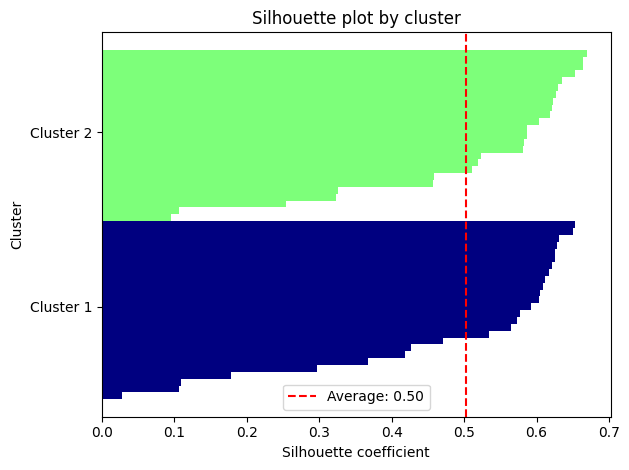

In [28]:
silhoutte_score_h1_2 = plot_silhouette(ym_c2_ni20_maxi500_pca2_h1, pca_df_h1_2)

In [29]:
clusters_pca2_h1 = pca_df_h1_2.copy()
clusters_pca2_h1['cluster'] = ym_c2_ni20_maxi500_pca2_h1.labels_

In [30]:
clusters_pca2_h1['Country'] = countries_win6_h1.Country

In [31]:
import country_converter as coco

In [32]:
clusters_pca2_h1['ISO_A3'] = coco.convert(names=clusters_pca2_h1['Country'], to='ISO3')

In [33]:
clusters_pca2_h1.loc[:, 'Continent'] = coco.convert(names=clusters_pca2_h1['Country'], to='continent')

In [34]:
def print_cluster_groups(df_clusters):
    """
    Groups countries by their cluster and prints each group with country name and continent.

    Parameters:
    - df_clusters: DataFrame containing 'Country', 'cluster', and 'CONTINENT' columns
    """

    # Ensure required columns exist
    required_cols = {'Country', 'cluster', 'Continent'}
    if not required_cols.issubset(df_clusters.columns):
        print("Missing required columns in the DataFrame.")
        return

    # Group countries by cluster
    grouped = df_clusters.groupby('cluster')

    # Print each cluster group
    for cluster_id, group in grouped:
        print(f"\n🌍 Cluster {cluster_id} ({len(group)} countries):")
        for _, row in group.iterrows():
            country = row['Country']
            continent = row['Continent']
            print(f" - {country} ({continent})")

In [35]:
print_cluster_groups(clusters_pca2_h1)


🌍 Cluster 0 (26 countries):
 - Australia (Oceania)
 - Austria (Europe)
 - Belgium (Europe)
 - Brazil (America)
 - Bulgaria (Europe)
 - Canada (America)
 - Chile (America)
 - Colombia (America)
 - Croatia (Europe)
 - Cyprus (Asia)
 - Czech (Europe)
 - Denmark (Europe)
 - Estonia (Europe)
 - Finland (Europe)
 - France (Europe)
 - Germany (Europe)
 - Greece (Europe)
 - Hungary (Europe)
 - Iceland (Europe)
 - Ireland (Europe)
 - Israel (Asia)
 - Italy (Europe)
 - Japan (Asia)
 - Latvia (Europe)
 - Lithuania (Europe)
 - Luxembourg (Europe)

🌍 Cluster 1 (25 countries):
 - Malaysia (Asia)
 - Malta (Europe)
 - Mexico (America)
 - Netherlands (Europe)
 - New Zealand (Oceania)
 - Norway (Europe)
 - Paraguay (America)
 - Peru (America)
 - Philippines (Asia)
 - Poland (Europe)
 - Portugal (Europe)
 - Romania (Europe)
 - Russia (Europe)
 - Serbia (Europe)
 - Singapore (Asia)
 - Slovakia (Europe)
 - Slovenia (Europe)
 - South Africa (Africa)
 - South Korea (Asia)
 - Spain (Europe)
 - Sweden (Europe

In [36]:
clusters_pca2_h1['Country'] = clusters_pca2_h1['Country'].replace('Czech','Czech Republic')

### Import and clean data for create synthetic data
* Import the data for hpi by country
* Observe if have Pararguay country
* Look if have the same countries that the df with the culsters
* Look if the name of the countries are in the same format "-" or "_"
* Delete countries that do not exist in the HPI dataframe

In [37]:
df_hpi_winsorized = pd.read_parquet('../data/hpi_3_deleted_countries_winsorized4.parquet')

In [38]:
clusters_pca2_h1.shape

(51, 6)

In [39]:
clusters_pca2_h1.head()

,PC1,PC2,cluster,Country,ISO_A3,Continent
0,-25.502856,3.175044,0,Australia,AUS,Oceania
1,-25.020107,-3.528185,0,Austria,AUT,Europe
2,-23.965987,-2.623623,0,Belgium,BEL,Europe
3,-22.032555,8.614890,0,Brazil,BRA,America
4,-22.185022,-5.876868,0,Bulgaria,BGR,Europe


In [40]:
df_hpi_winsorized.shape

(15, 51)

### Leverage The Law of Large Numbers
* Run the sampling process for each cluster, exclude one country of that cluster to compare

In [41]:
import random

In [42]:
def evaluate_cluster_sampling_errors(df_hpi, df_clusters, cluster_id,
                                     cluster_column='cluster', country_column='Country',
                                     year_column='Year', sample_size=30, n_samples=1000,
                                     plot=True, seed=None):
    """
    Evaluates synthetic HPI estimation via bootstrap sampling for each country in a cluster.

    Returns:
    - avg_mse: Average MSE across all countries in the cluster
    - avg_mae: Average MAE across all countries in the cluster
    - best_country: Country with the lowest MSE
    - yearly_bootstrap_means: Dict with year as key and synthetic mean using best_country as excluded
    - yearly_mean: Dict with year as key and actual mean HPI of all countries in the cluster
    """
    if seed is not None:
        random.seed(seed)
        np.random.seed(seed)

    all_cluster_countries = df_clusters[df_clusters[cluster_column] == cluster_id][country_column].tolist()
    cluster_countries = [c for c in all_cluster_countries if c in df_hpi.columns]

    if len(cluster_countries) < 2:
        raise ValueError("Cluster must contain at least two countries present in HPI data.")

    mse_scores = {}
    mae_scores = {}

    for excluded_country in cluster_countries:
        sampling_countries = [c for c in cluster_countries if c != excluded_country]
        synthetic_values = []
        actual_values = []

        for _, row in df_hpi.iterrows():
            year = row[year_column]
            values = row[sampling_countries].dropna().values
            actual_value = row.get(excluded_country, np.nan)

            if len(values) == 0 or np.isnan(actual_value):
                continue

            sample_means = [np.mean(np.random.choice(values, size=sample_size, replace=True))
                            for _ in range(n_samples)]
            synthetic_mean = np.mean(sample_means)

            synthetic_values.append(synthetic_mean)
            actual_values.append(actual_value)

        if len(synthetic_values) == 0:
            mse_scores[excluded_country] = np.nan
            mae_scores[excluded_country] = np.nan
        else:
            errors = np.array(synthetic_values) - np.array(actual_values)
            mse_scores[excluded_country] = np.mean(errors ** 2)
            mae_scores[excluded_country] = np.mean(np.abs(errors))

    best_country = min(mse_scores, key=lambda k: mse_scores[k] if not np.isnan(mse_scores[k]) else np.inf)

    # Plot for best country
    if plot:
        synthetic_values = []
        actual_values = []
        years = []

        sampling_countries = [c for c in cluster_countries if c != best_country]

        for _, row in df_hpi.iterrows():
            year = row[year_column]
            values = row[sampling_countries].dropna().values
            actual_value = row.get(best_country, np.nan)

            if len(values) == 0 or np.isnan(actual_value):
                continue

            sample_means = [np.mean(np.random.choice(values, size=sample_size, replace=True))
                            for _ in range(n_samples)]
            cumulative_means = [np.mean(sample_means[:j+1]) for j in range(n_samples)]

            lower_bound = np.percentile(sample_means, 2.5)
            upper_bound = np.percentile(sample_means, 97.5)

            fig, axes = plt.subplots(1, 2, figsize=(14, 4))

            axes[0].hist(sample_means, bins=30, color='lightgreen', edgecolor='black')
            axes[0].axvline(actual_value, color='red', linestyle='--', label=f"Actual: {best_country}")
            axes[0].axvline(lower_bound, color='blue', linestyle=':', label='95% CI Lower')
            axes[0].axvline(upper_bound, color='blue', linestyle=':', label='95% CI Upper')
            axes[0].set_title(f"HPI Sampling Distribution - Year {year}")
            axes[0].set_xlabel("Sample Mean HPI")
            axes[0].set_ylabel("Frequency")
            axes[0].legend()
            axes[0].grid(True)

            axes[1].plot(cumulative_means, color='purple')
            axes[1].axhline(np.mean(sample_means), color='gray', linestyle='--', label='Final Mean')
            axes[1].set_title("Mean Convergence Over Iterations")
            axes[1].set_xlabel("Iteration")
            axes[1].set_ylabel("Cumulative Mean")
            axes[1].legend()
            axes[1].grid(True)

            plt.tight_layout()
            plt.show()

    # Synthetic mean per year using best_country as excluded
    yearly_bootstrap_means = {}
    sampling_countries = [c for c in cluster_countries if c != best_country]

    for _, row in df_hpi.iterrows():
        year = row[year_column]
        values = row[sampling_countries].dropna().values

        if len(values) == 0:
            continue

        sample_means = [np.mean(np.random.choice(values, size=sample_size, replace=True))
                        for _ in range(n_samples)]
        synthetic_mean = np.mean(sample_means)
        yearly_bootstrap_means[year] = synthetic_mean

    # Real mean per year using all countries in the cluster
    yearly_mean = {}
    for _, row in df_hpi.iterrows():
        year = row[year_column]
        values = row[cluster_countries].dropna().values

        if len(values) == 0:
            continue

        yearly_mean[year] = np.mean(values)

    avg_mse = np.nanmean(list(mse_scores.values()))
    avg_mae = np.nanmean(list(mae_scores.values()))

    return avg_mse, avg_mae, best_country, yearly_bootstrap_means, yearly_mean

In [43]:
def calculate_hpi_variance_by_cluster(df_hpi, df_clusters,
                                      cluster_column='cluster', country_column='Country',
                                      year_column='Year'):
    """
    Calculates average HPI variance across countries for each cluster.

    Parameters:
    - df_hpi: DataFrame with HPI values (columns = countries, rows = years, plus 'Year' column)
    - df_clusters: DataFrame with country names and cluster assignments
    - cluster_column: Column name in df_clusters with cluster labels
    - country_column: Column name in df_clusters with country names
    - year_column: Column name in df_hpi with year values

    Returns:
    - cluster_variances: dict with cluster_id as key and average variance as value
    """
    cluster_variances = {}

    for cluster_id in sorted(df_clusters[cluster_column].unique()):
        # Get countries in this cluster that are present in HPI data
        countries = df_clusters[df_clusters[cluster_column] == cluster_id][country_column].tolist()
        cluster_countries = [c for c in countries if c in df_hpi.columns]

        if len(cluster_countries) < 2:
            cluster_variances[cluster_id] = np.nan
            continue

        # Extract HPI values for cluster countries
        hpi_values = df_hpi[cluster_countries]

        # Calculate variance across countries for each year
        yearly_variances = hpi_values.var(axis=1, skipna=True)

        # Compute average variance across all years
        avg_variance = yearly_variances.mean()
        cluster_variances[cluster_id] = avg_variance

    return cluster_variances

In [44]:
def plot_cluster_hpi_with_bootstrap(df_hpi, df_clusters, cluster_id,
                                    yearly_bootstrap_means,
                                    yearly_mean,
                                    cluster_column='cluster', country_column='Country',
                                    year_column='Year'):
    """
    Plots HPI values for each country in a cluster over time,
    along with the synthetic bootstrap mean per year and the actual cluster mean.

    Parameters:
    - df_hpi: DataFrame with HPI values (columns = countries, rows = years, plus 'Year' column)
    - df_clusters: DataFrame with country names and cluster assignments
    - cluster_id: Cluster number to plot
    - yearly_bootstrap_means: Dict with year as key and synthetic mean value
    - yearly_mean: Dict with year as key and actual mean HPI of all countries in the cluster
    """
    # Obtener países del cluster
    cluster_countries = df_clusters[df_clusters[cluster_column] == cluster_id][country_column].tolist()
    cluster_countries = [c for c in cluster_countries if c in df_hpi.columns]

    if len(cluster_countries) == 0:
        raise ValueError("No hay países válidos en el cluster para graficar.")

    # Graficar HPI real por país
    plt.figure(figsize=(12, 6))
    for country in cluster_countries:
        country_data = df_hpi[[year_column, country]].dropna()
        plt.plot(country_data[year_column], country_data[country], label=country, alpha=0.6)

    # Graficar curva sintética del bootstrap
    bootstrap_years = sorted(yearly_bootstrap_means.keys())
    bootstrap_values = [yearly_bootstrap_means[year] for year in bootstrap_years]
    plt.plot(bootstrap_years, bootstrap_values, label='Bootstrap Mean', color='black', linewidth=2.5)

    # Graficar media real del cluster (línea discontinua)
    mean_years = sorted(yearly_mean.keys())
    mean_values = [yearly_mean[year] for year in mean_years]
    plt.plot(mean_years, mean_values, label='Real Cluster Mean', color='gray', linestyle='--', linewidth=2.5)

    # Estética del gráfico
    plt.title(f"HPI por País en Cluster {cluster_id} + Medias Sintéticas y Reales")
    plt.xlabel("Año")
    plt.ylabel("Índice HPI")
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.show()

In [45]:
def count_points_within_iqr_by_cluster(df_hpi, df_clusters,
                                       cluster_column='cluster', country_column='Country',
                                       year_column='Year'):
    """
    Cuenta cuántos puntos de HPI están dentro del IQR (Q1–Q3) por cluster.

    Returns:
    - dict con cluster_id como clave y cantidad total de puntos dentro del IQR como valor
    """
    cluster_iqr_counts = {}

    for cluster_id in sorted(df_clusters[cluster_column].unique()):
        # Obtener países del cluster presentes en df_hpi
        countries = df_clusters[df_clusters[cluster_column] == cluster_id][country_column].tolist()
        cluster_countries = [c for c in countries if c in df_hpi.columns]

        if len(cluster_countries) < 2:
            cluster_iqr_counts[cluster_id] = 0
            continue

        # Extraer valores de HPI para esos países
        hpi_values = df_hpi[cluster_countries]

        total_within_iqr = 0

        # Iterar por año
        for _, row in hpi_values.iterrows():
            values = row.dropna().values
            if len(values) < 2:
                continue

            q1 = np.percentile(values, 25)
            q3 = np.percentile(values, 75)

            # Contar cuántos valores están dentro del IQR
            count = np.sum((values >= q1) & (values <= q3))
            total_within_iqr += count

        cluster_iqr_counts[cluster_id] = total_within_iqr

    return cluster_iqr_counts

In [46]:
def plot_kmeans_clusters(df, x_col, y_col, model, cluster_col='cluster', country_col='Country', highlight_country='Paraguay'):
    # Extraer coordenadas
    X = df[[x_col, y_col]].values
    y_km = df[cluster_col].values
    countries = df[country_col].values

    # Crear figura
    plt.figure(figsize=(10, 6))

    # Colores y marcadores por cluster
    colors = ['lightgreen', 'orange', 'lightblue', 'purple', 'gold', 'pink', 'gray', 'brown', 'cyan', 'red']
    markers = ['o', 's', 'v', '^', '<', '>', 'D', 'p', '*', 'h']
    special_marker = 'X'  # marcador especial para Paraguay

    # Graficar cada cluster
    for i in range(model.n_clusters):
        cluster_mask = (y_km == i)
        cluster_color = colors[i]
        cluster_marker = markers[i]

        # Separar Paraguay del resto
        paraguay_mask = cluster_mask & (countries == highlight_country)
        others_mask = cluster_mask & (countries != highlight_country)

        # Graficar otros países del cluster
        plt.scatter(X[others_mask, 0], X[others_mask, 1],
                    s=50, c=cluster_color, marker=cluster_marker,
                    edgecolor='black', label=f'Cluster {i}')

        # Graficar Paraguay con marcador especial
        if paraguay_mask.any():
            plt.scatter(X[paraguay_mask, 0], X[paraguay_mask, 1],
                        s=100, c=cluster_color, marker=special_marker,
                        edgecolor='black', label=f'{highlight_country} (Cluster {i})')

    # Graficar centroides
    plt.scatter(model.cluster_centers_[:, 0], model.cluster_centers_[:, 1],
                s=250, marker='*', c='red', edgecolor='black', label='Centroids')

    plt.xlabel(x_col)
    plt.ylabel(y_col)
    plt.legend(scatterpoints=1)
    plt.grid(True)
    plt.tight_layout()
    plt.title(f'K-Means Clustering: {x_col} vs {y_col}')
    plt.show()

In [47]:
def plot_hpi_dispersion_by_cluster(df_hpi, df_clusters,
                                    cluster_column='cluster', country_column='Country',
                                    year_column='Year'):
    """
    Plots the dispersion of HPI values for each cluster using boxplots.

    Parameters:
    - df_hpi: DataFrame with HPI values (columns = countries, rows = years, plus 'Year' column)
    - df_clusters: DataFrame with country names and cluster assignments
    - cluster_column: Column name in df_clusters with cluster labels
    - country_column: Column name in df_clusters with country names
    - year_column: Column name in df_hpi with year values
    """
    # Crear lista para almacenar datos
    records = []

    # Iterar sobre cada cluster
    for cluster_id in sorted(df_clusters[cluster_column].unique()):
        countries = df_clusters[df_clusters[cluster_column] == cluster_id][country_column].tolist()
        cluster_countries = [c for c in countries if c in df_hpi.columns]

        if len(cluster_countries) < 2:
            continue

        # Extraer valores de HPI por país y año
        for _, row in df_hpi.iterrows():
            year = row[year_column]
            for country in cluster_countries:
                value = row.get(country, np.nan)
                if not np.isnan(value):
                    records.append({
                        'Cluster': f'Cluster {cluster_id}',
                        'Country': country,
                        'Year': year,
                        'HPI': value
                    })

    # Convertir a DataFrame
    df_plot = pd.DataFrame(records)

    # Crear boxplot
    plt.figure(figsize=(12, 6))
    sns.boxplot(hue='Cluster', y='HPI', data=df_plot, palette='Set2', x='Cluster')
    plt.title('HPI Dispersion by Cluster')
    plt.ylabel('Human Potential Index (HPI)')
    plt.xlabel('Cluster')
    plt.grid(True)
    plt.tight_layout()
    plt.show()

### pca2

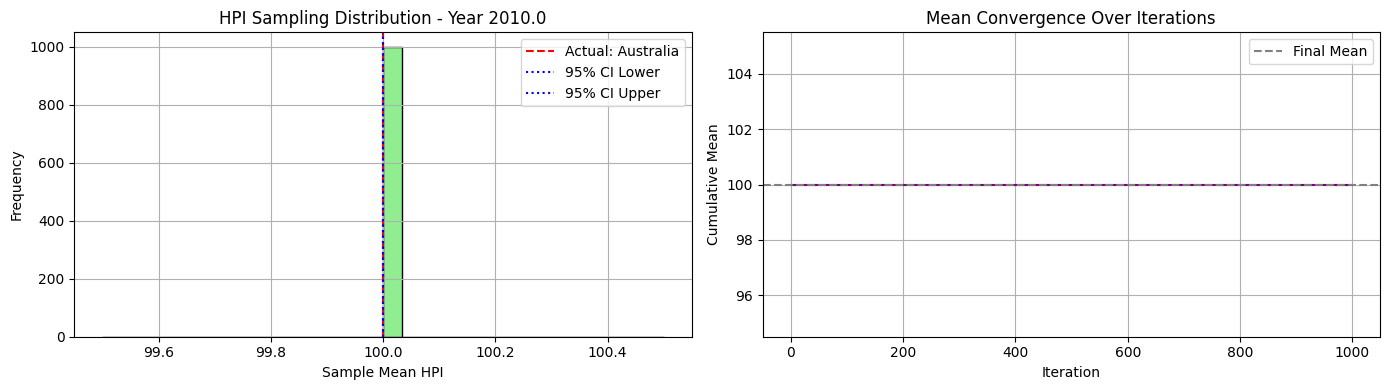

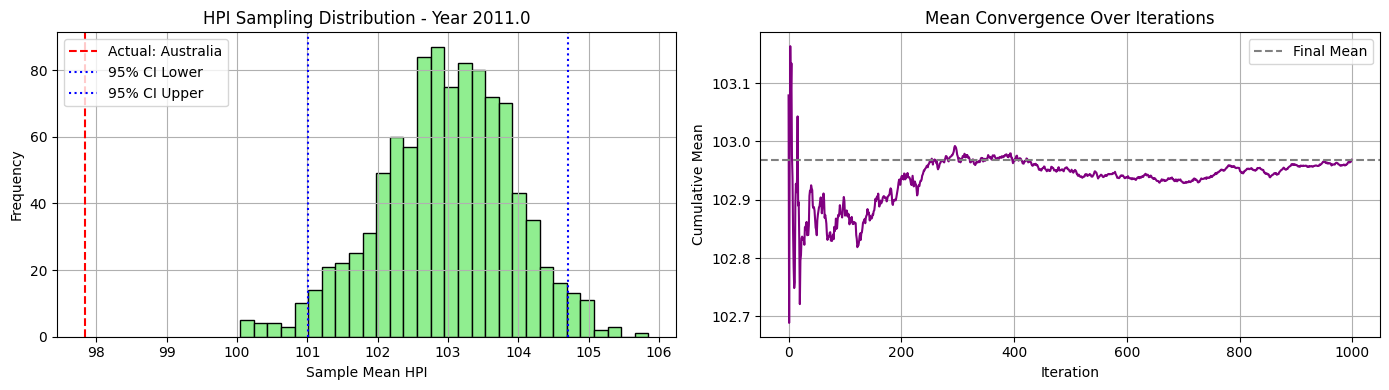

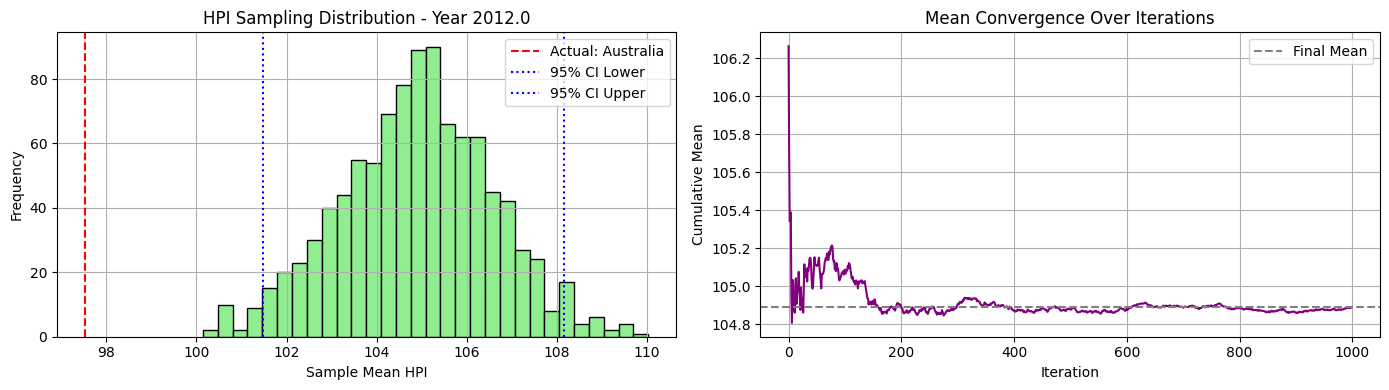

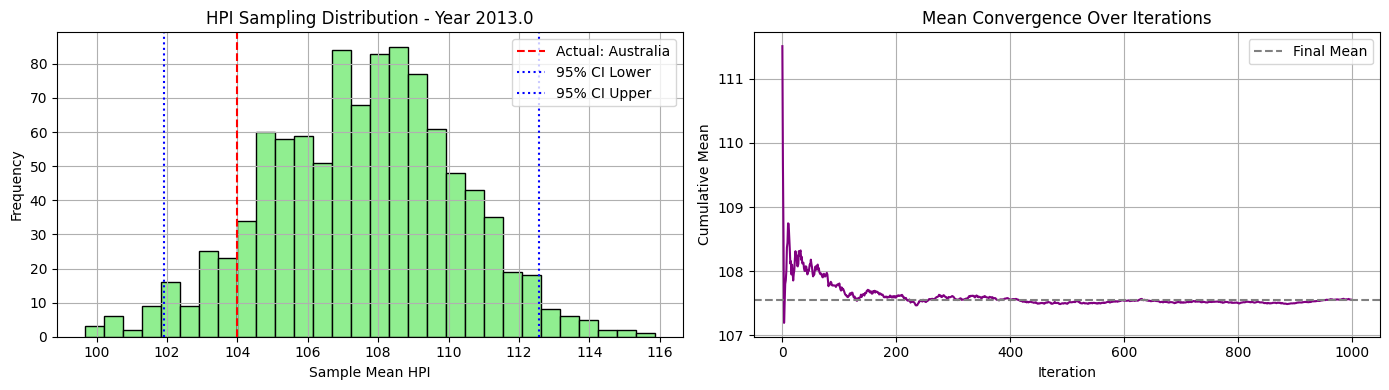

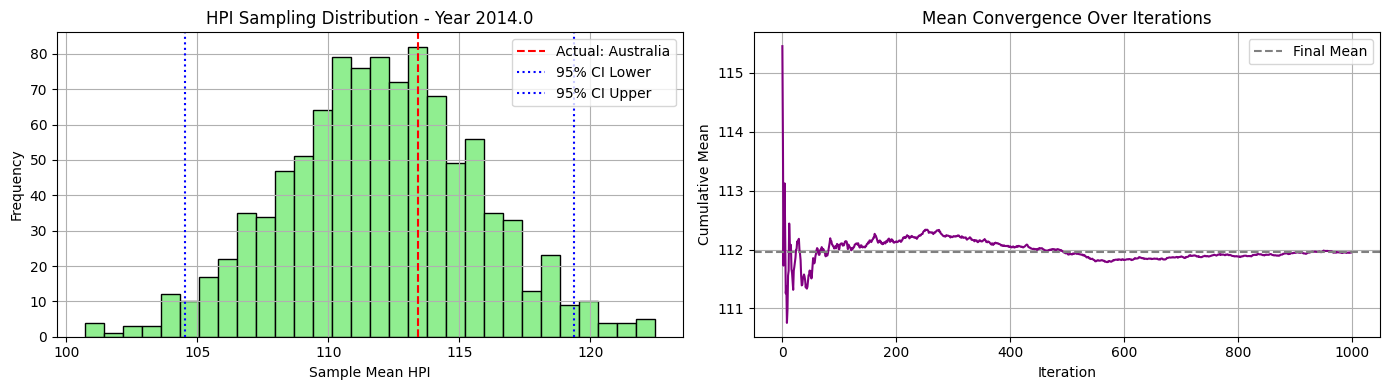

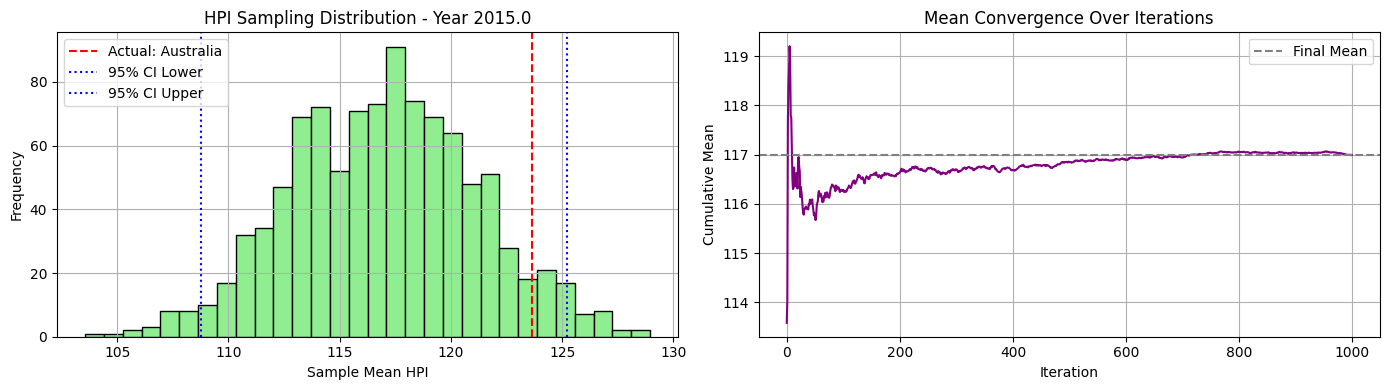

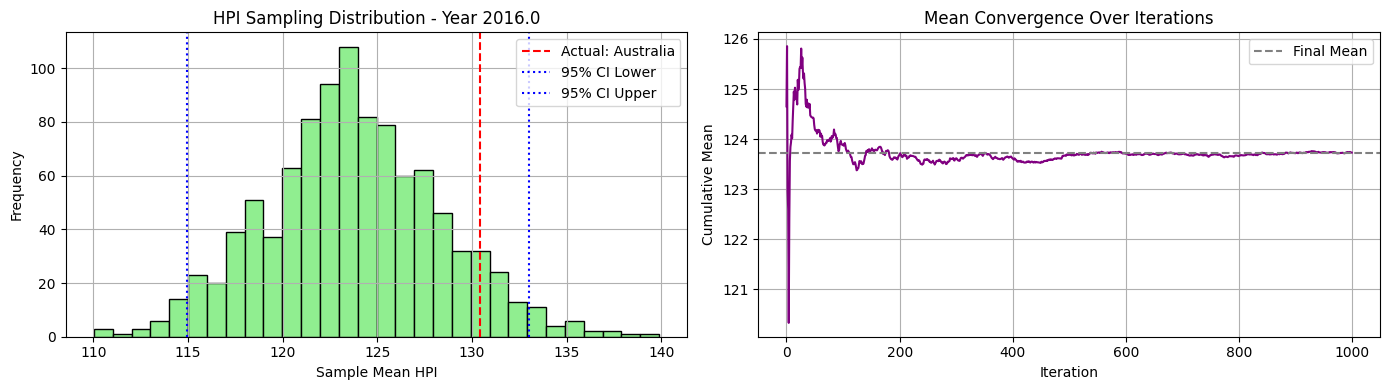

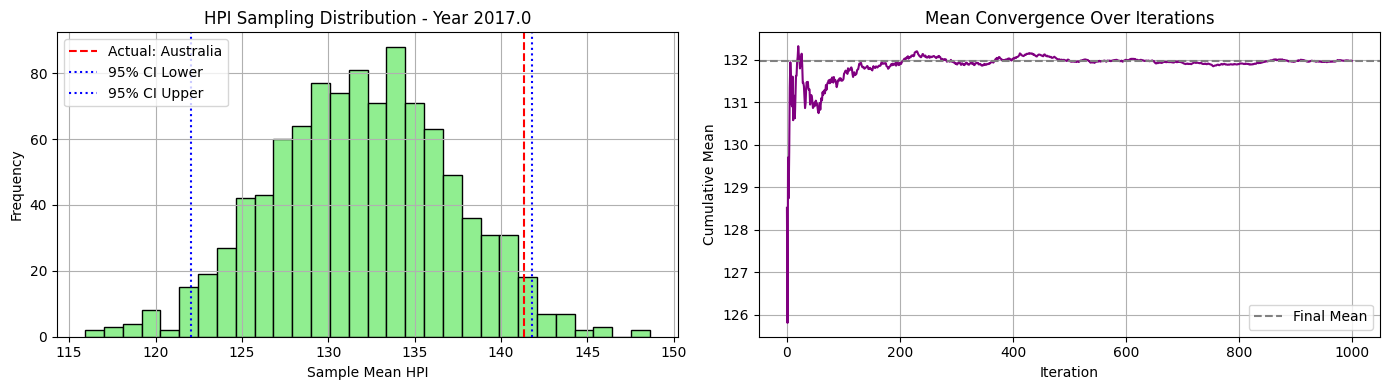

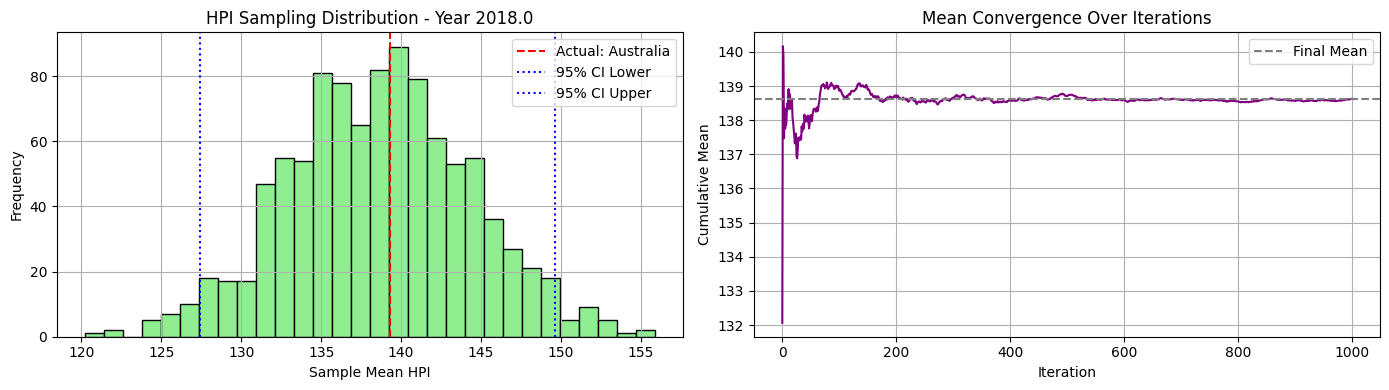

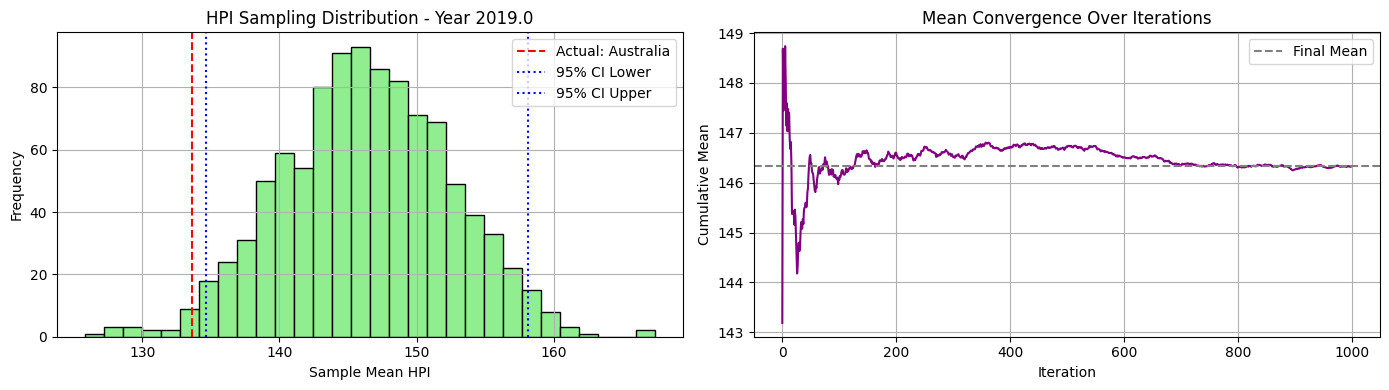

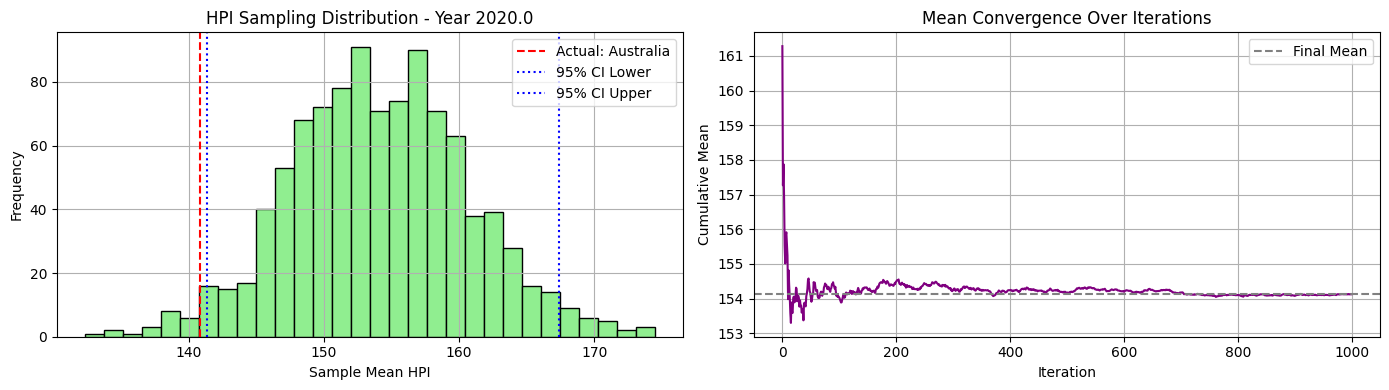

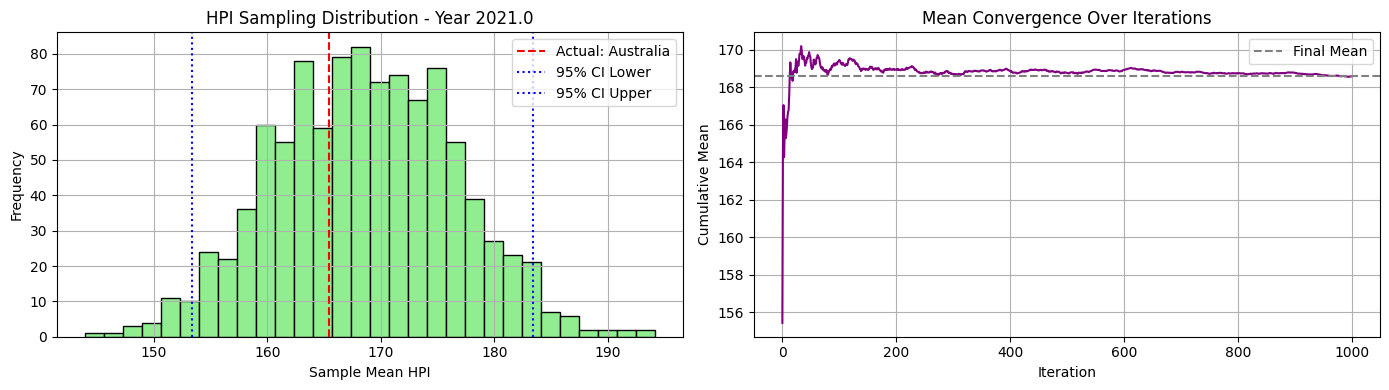

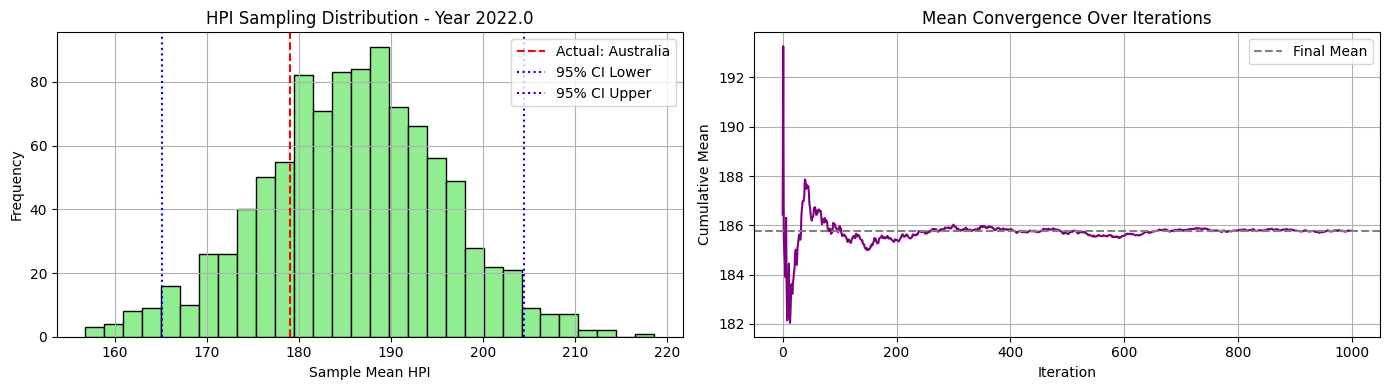

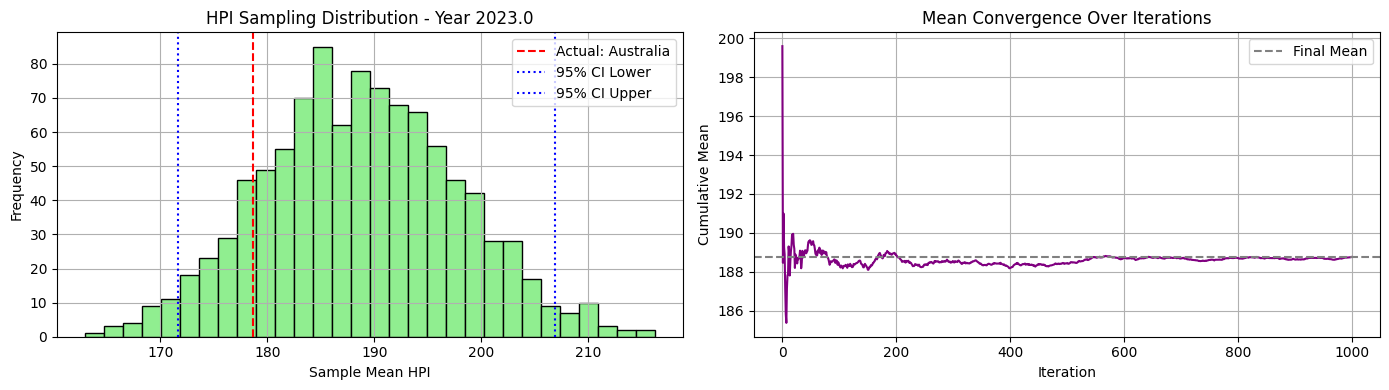

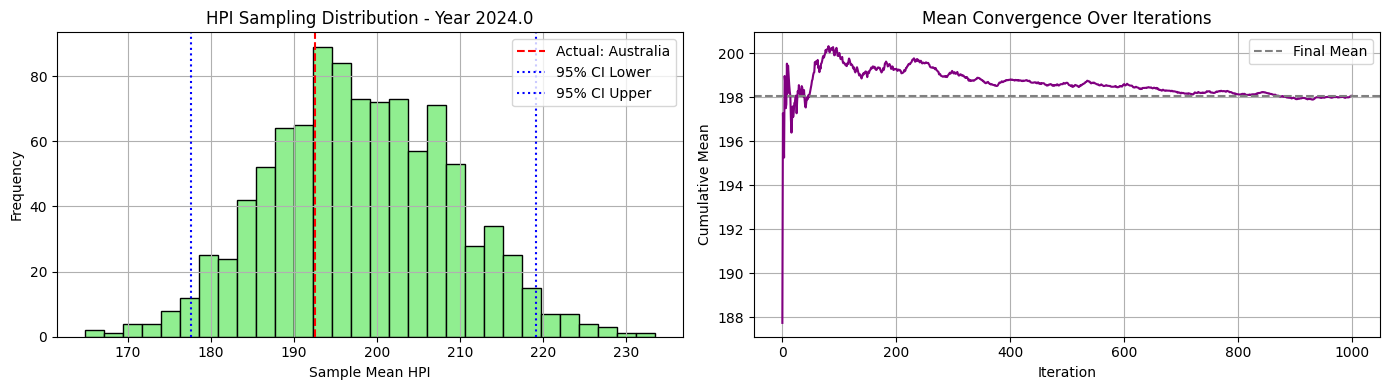

In [48]:
avg_mse_00, avg_mae_00, best_country_00, yearly_bootstrap_means_00, yearly_mean_00 = evaluate_cluster_sampling_errors(df_hpi_winsorized, clusters_pca2_h1, cluster_id=0)

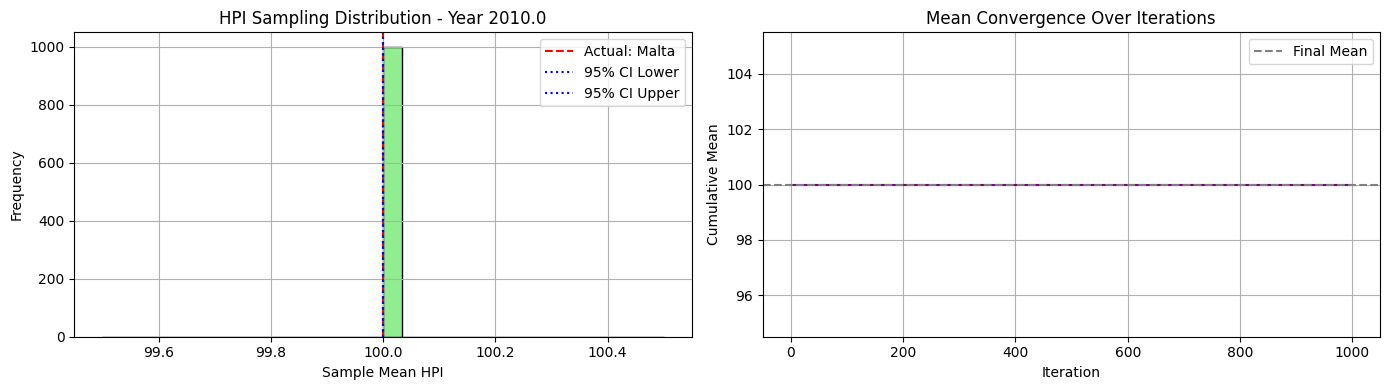

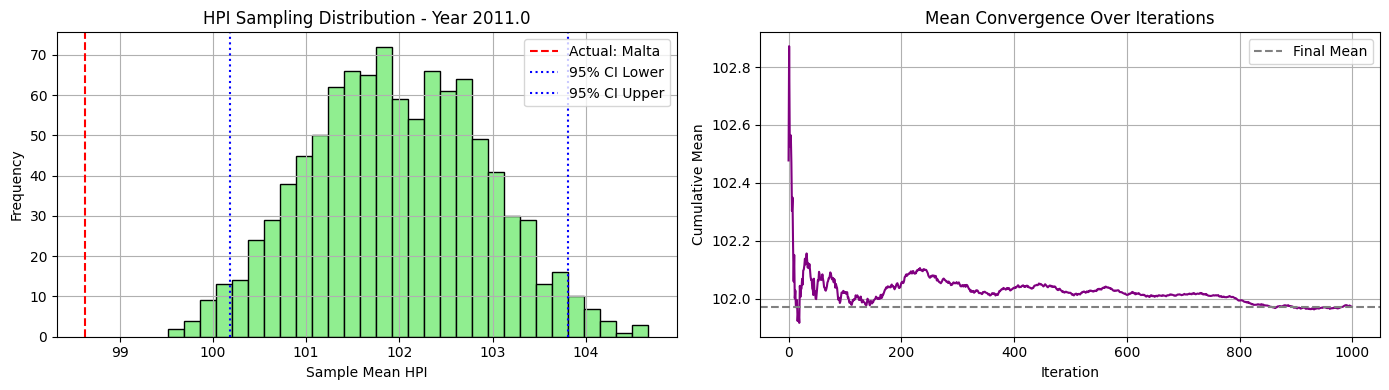

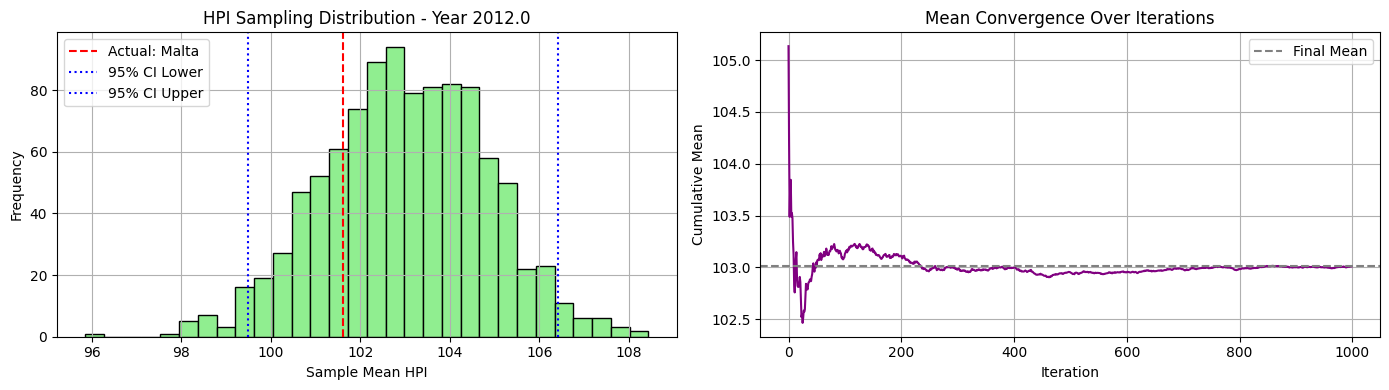

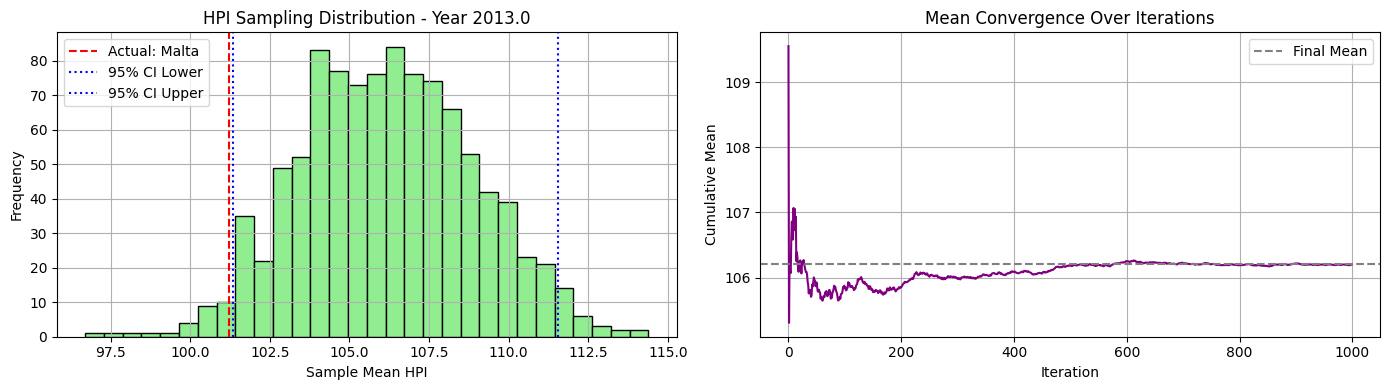

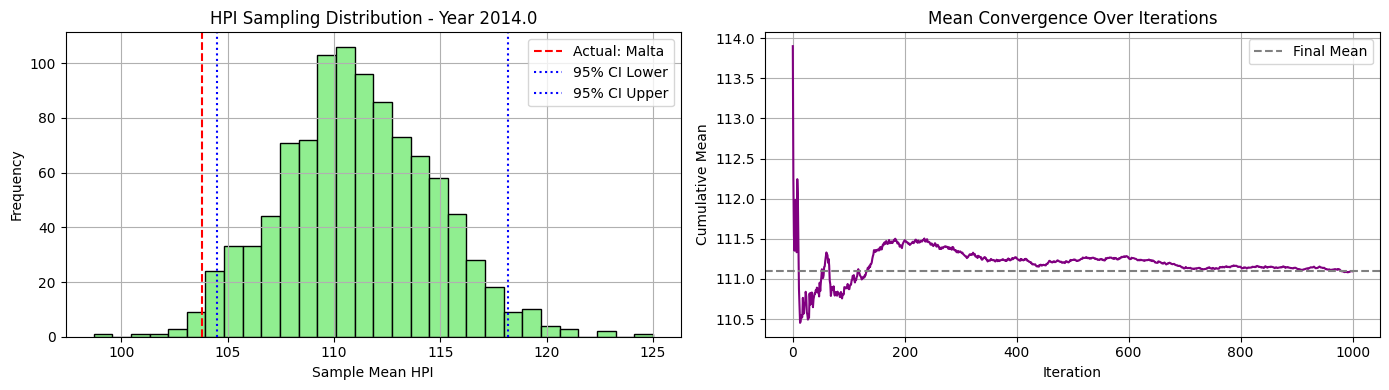

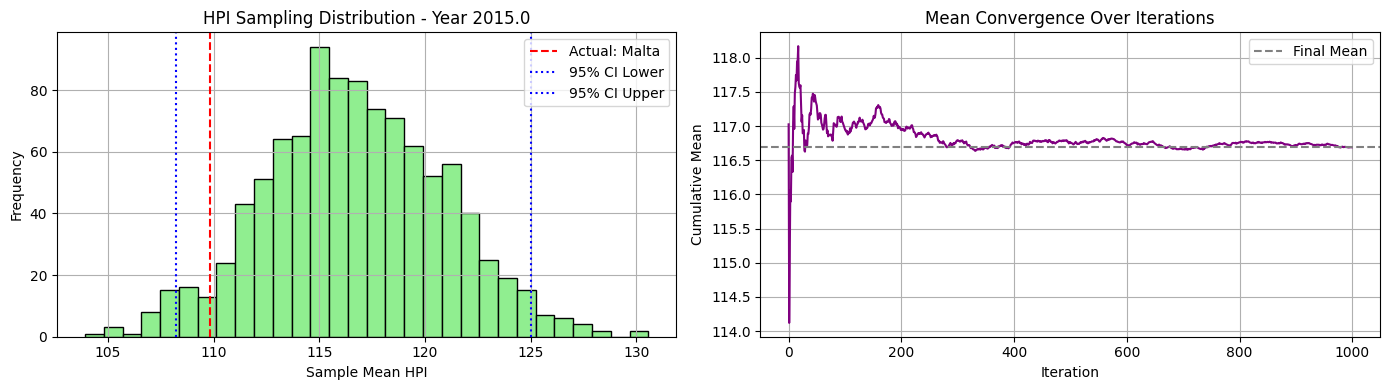

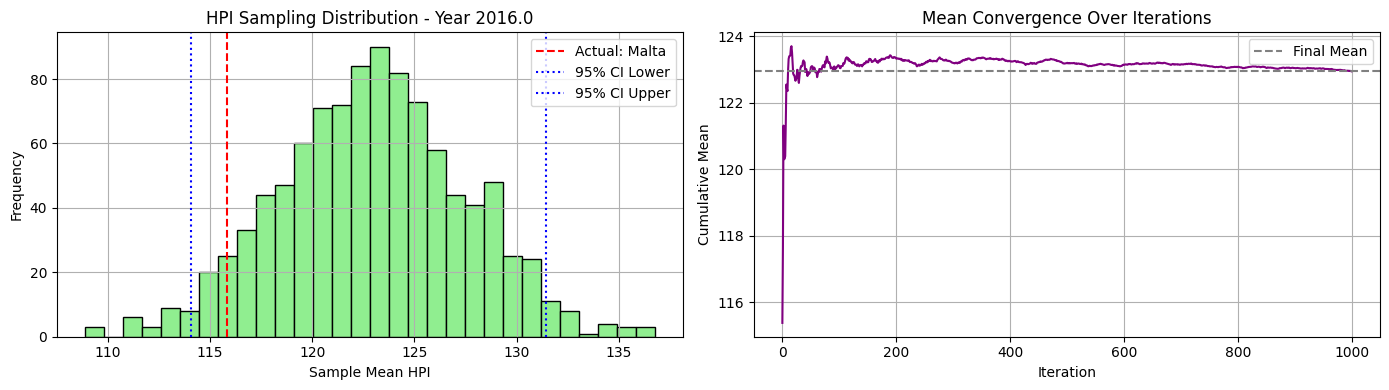

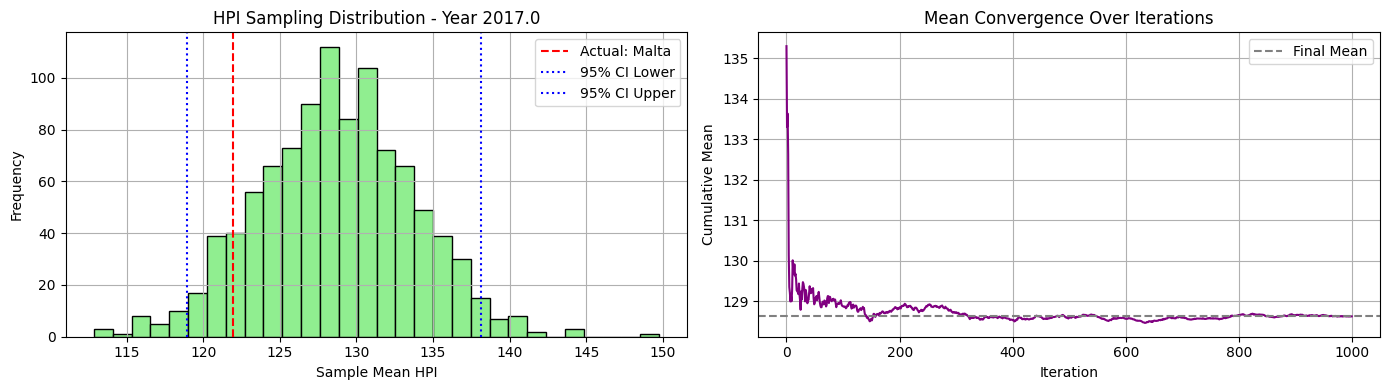

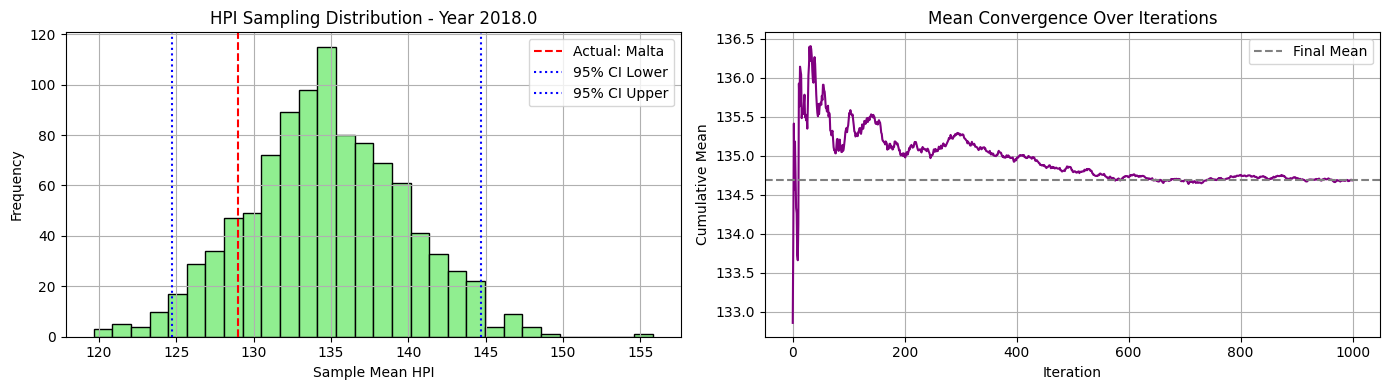

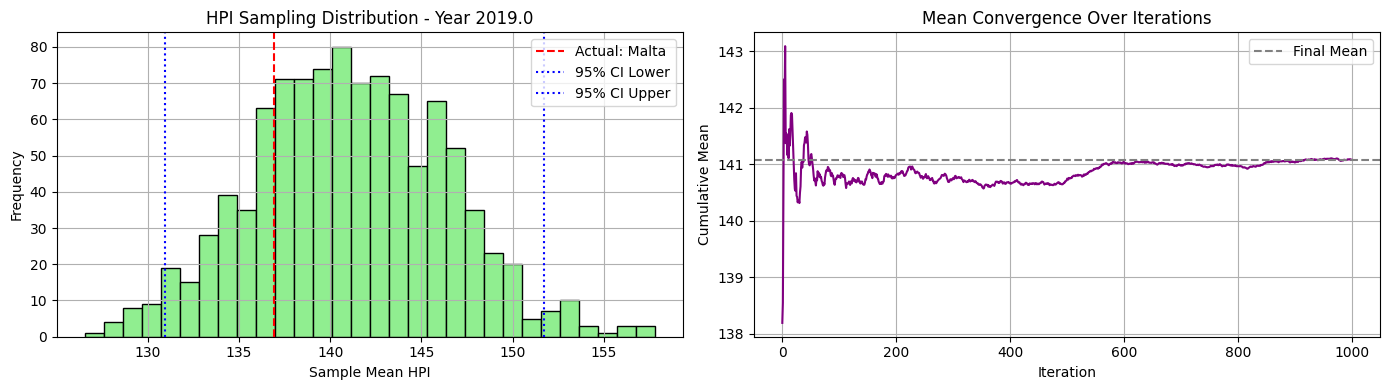

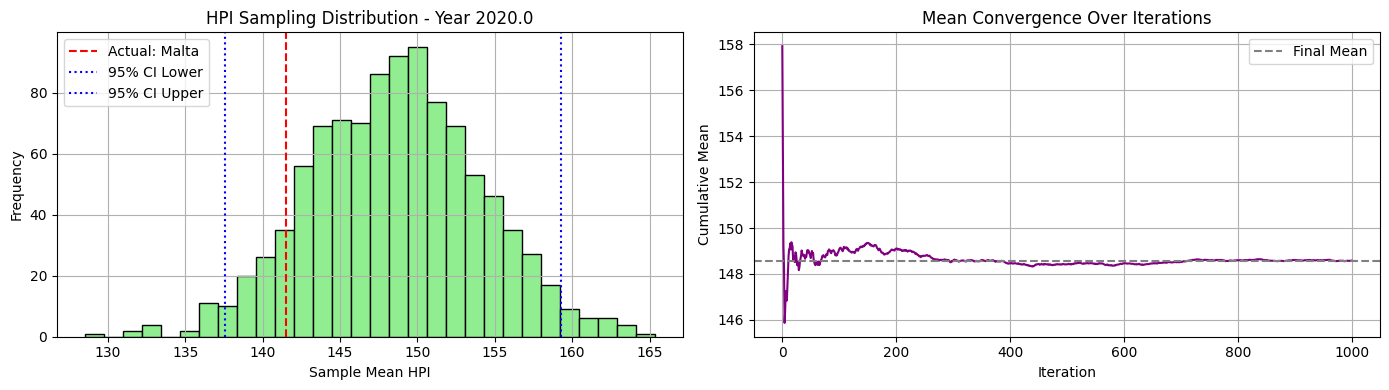

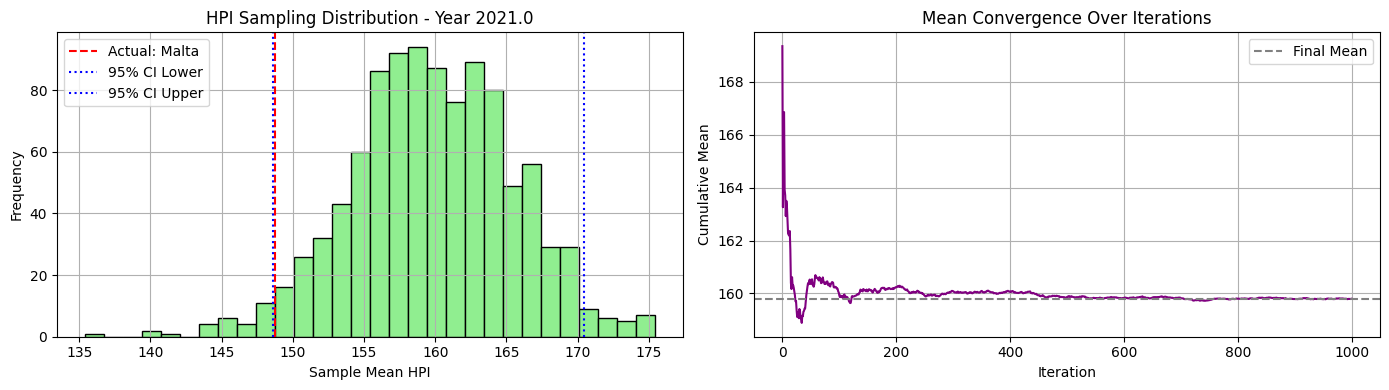

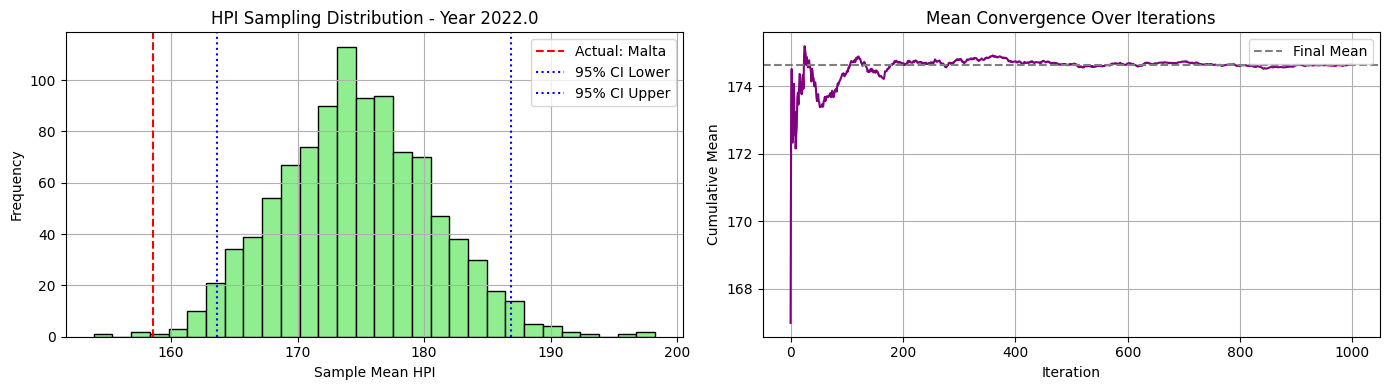

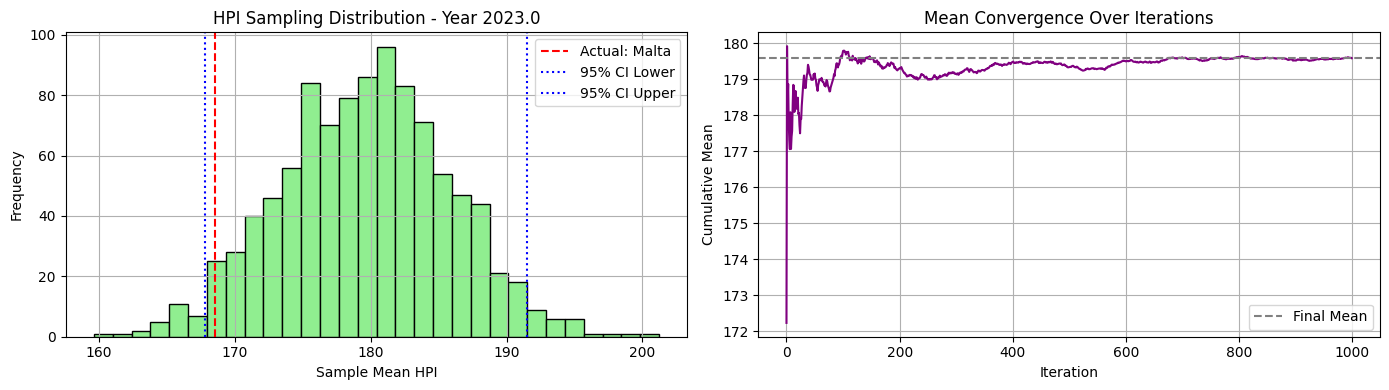

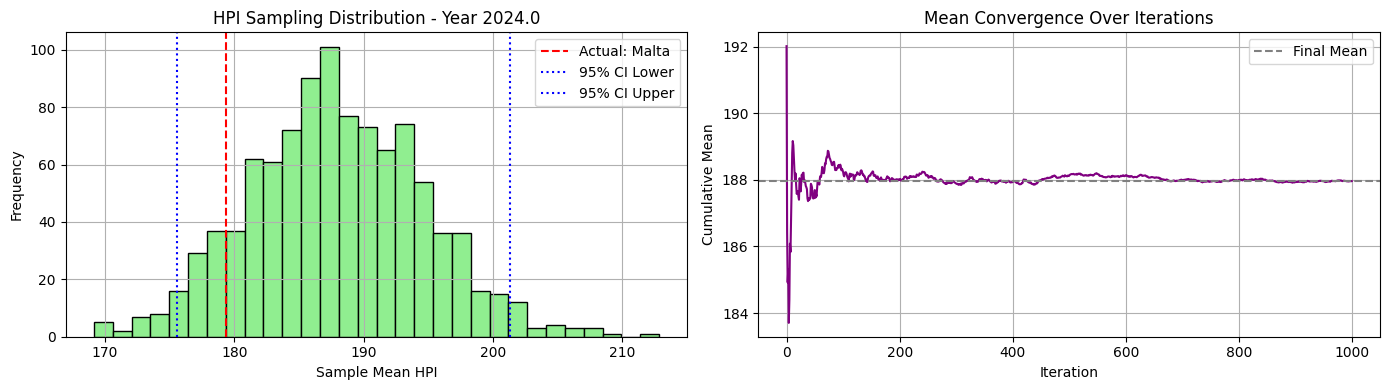

In [49]:
avg_mse_01, avg_mae_01, best_country_01, yearly_bootstrap_means_01, yearly_mean_01 = evaluate_cluster_sampling_errors(df_hpi_winsorized, clusters_pca2_h1, cluster_id=1)

### Compute metrics
* Compute MSE from synthetic data versus the real one from the country excluded
* Compute MAE from synthetic data versus the real one from the country excluded

In [50]:
from sklearn.metrics import mean_squared_error, mean_absolute_error

In [51]:
errors_h1 = {
    'cluster_0': [avg_mse_00, avg_mae_00],
    'cluster_1': [avg_mse_01, avg_mae_01]
}

In [52]:
# Convertir a DataFrame
df_errors_h1 = pd.DataFrame.from_dict(errors_h1, orient='index', columns=['Average MSE', 'Average MAE'])

# Formatear valores con 4 decimales
df_errors_h1 = df_errors_h1.round(4)

# Imprimir tabla
print("\n📊 Cluster Sampling Error Summary:")
print(df_errors_h1)


📊 Cluster Sampling Error Summary:
           Average MSE  Average MAE
cluster_0    1167.0317      25.6916
cluster_1     687.8998      19.6694


In [53]:
df_errors_h1['Average MSE'].mean()

np.float64(927.4657500000001)

In [54]:
df_errors_h1['Average MAE'].mean()

np.float64(22.680500000000002)

In [55]:
variances_h1 = calculate_hpi_variance_by_cluster(df_hpi_winsorized, clusters_pca2_h1)
for cluster_id, var in variances_h1.items():
    print(f"Cluster {cluster_id}: Avg HPI Variance = {var:.4f}")

Cluster 0: Avg HPI Variance = 1122.3366
Cluster 1: Avg HPI Variance = 658.5484


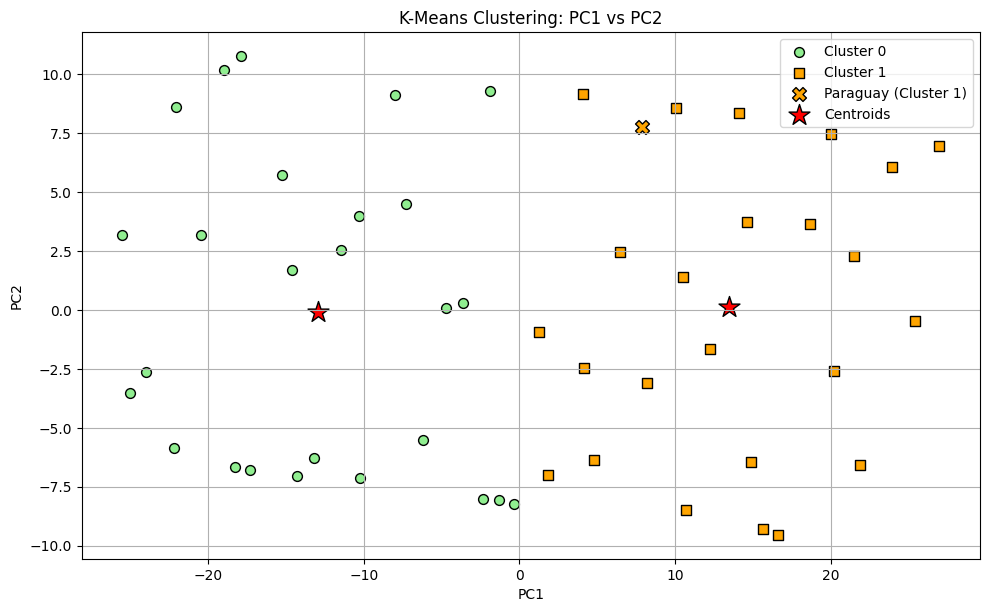

In [56]:
plot_kmeans_clusters(clusters_pca2_h1, 'PC1', 'PC2', km_c2_ni20_maxi500_pca2_h1)

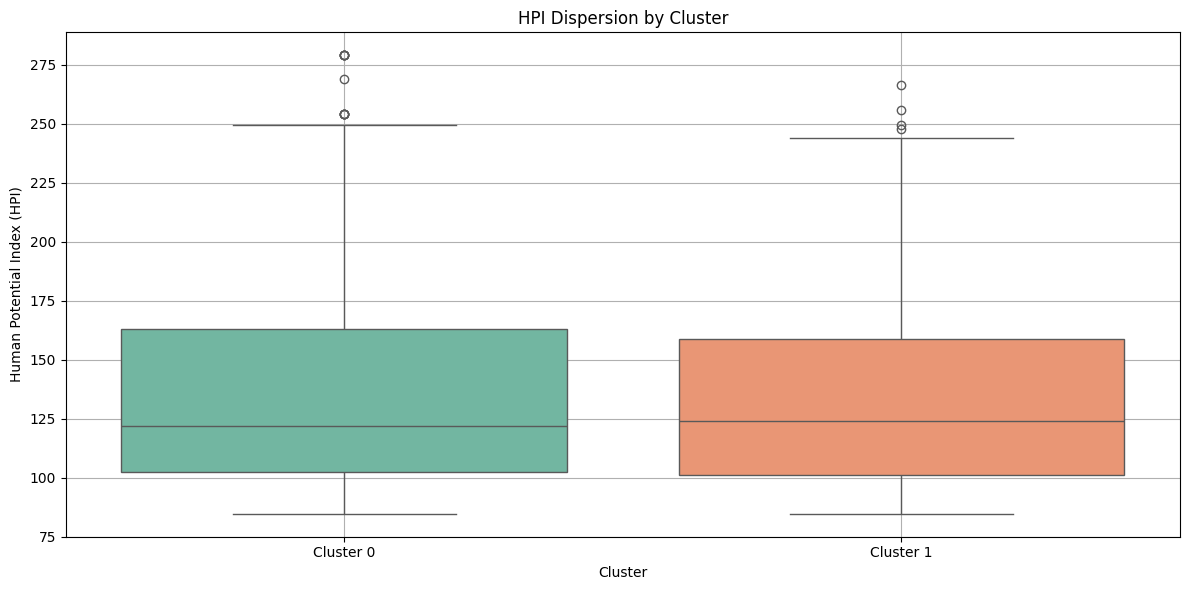

In [57]:
plot_hpi_dispersion_by_cluster(df_hpi_winsorized, clusters_pca2_h1)

In [58]:
iqr_points_h1 = count_points_within_iqr_by_cluster(df_hpi_winsorized, clusters_pca2_h1)
print(iqr_points_h1)

{np.int32(0): np.int64(195), np.int32(1): np.int64(192)}


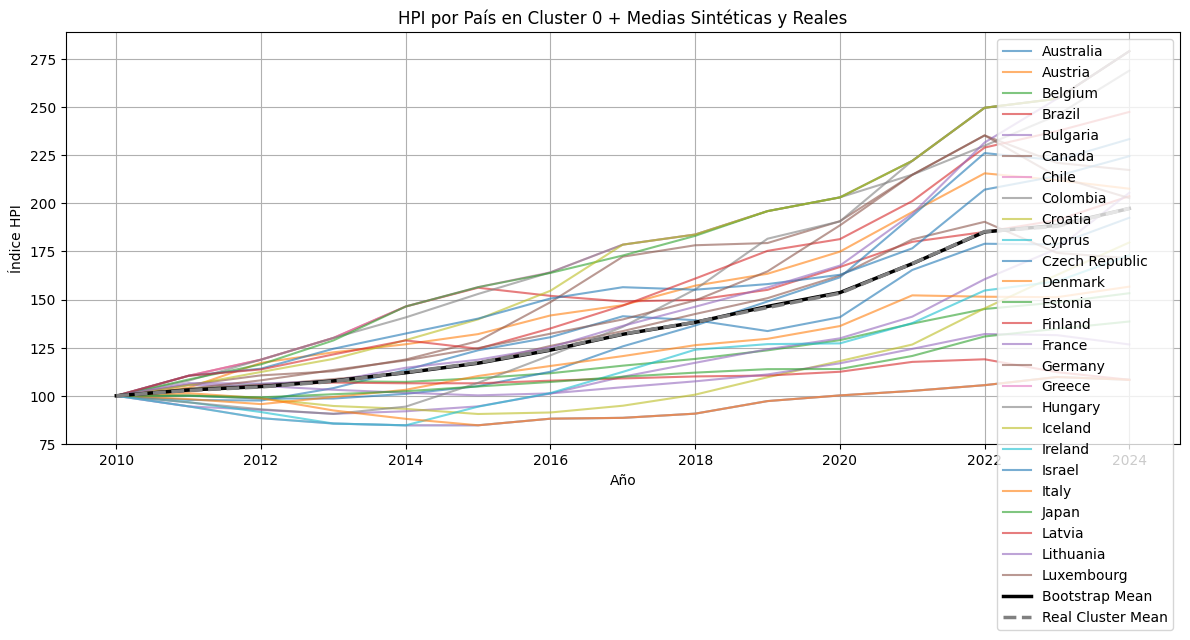

In [59]:
plot_cluster_hpi_with_bootstrap(df_hpi_winsorized, clusters_pca2_h1, cluster_id=0, cluster_column="cluster", yearly_bootstrap_means=yearly_bootstrap_means_00, yearly_mean=yearly_mean_00)

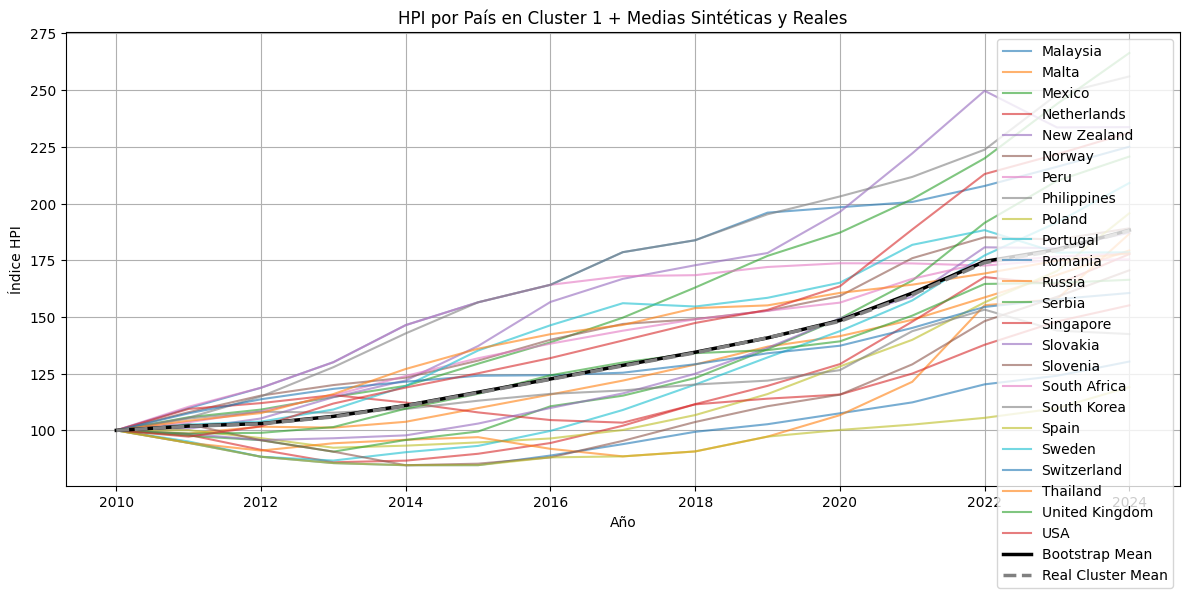

In [60]:
plot_cluster_hpi_with_bootstrap(df_hpi_winsorized, clusters_pca2_h1, cluster_id=1, cluster_column="cluster", yearly_bootstrap_means=yearly_bootstrap_means_01, yearly_mean=yearly_mean_01)

### Log performance of the experiment
* Import dataframe for the logs
* Define the hyperparameter for introduce the results
* Export the dataframe

In [61]:
from datetime import datetime

In [62]:
log_df = pd.read_parquet('../data/log_performance/clean_log_performance_experiments.parquet')

In [63]:
pd.set_option('display.max_columns', None)

In [64]:
log_df.tail()

,experiment_name,experiment_date,premacroecon_conversion_transform,countries_used_for_clustering,clustering_model,n_clusters,init_method,n_init,max_iter,random_state,used_elbow_method,used_silhouette_score,used_2nd_derivate_for_inflection,silhouette_score,transformations_clustering,outliers_handling_clustering,used_all_variables_for_clustering,used_pca_for_clustering,transformations_sampling,outliers_handling_sampling,sampling_method,sampling_seed,excluded_countries_count,mse_score,mae_score,source_notebook,pca_ratio_sum,pca_ratio_values,Variance_Cluster_0,Variance_Cluster_1,Variance_Cluster_2,IQR_Count_Cluster_0,IQR_Count_Cluster_1,IQR_Count_Cluster_2,Variance_Cluster_3,IQR_Count_Cluster_3
21,kmeans_plusplus_c2_ni20_maxi500_3cpuntries_del...,2025-09-20 22:43,None,50,KMeans,2,k-means++,20.0,500.0,42.0,True,True,1,0.563596,"StandardScaler, log transformation",Winsorization x6,True,True,"Winsorization x2, rounding",Winsorization x2,bootstrap,"[32, 43, 52]",3.0,246.836518,11.583352,hypothesis_test_29.ipynb,0.74038,"[0.6591137352377315, 0.08126612096581198]",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
22,kmeans_plusplus_c3_ni20_maxi500_3countries_del...,2025-09-20 22:46,None,50,KMeans,3,k-means++,20.0,500.0,42.0,True,True,1,0.562442,"StandardScaler, log transformation",Winsorization x6,True,True,"Winsorization x2, rounding",Winsorization x2,bootstrap,"[32, 43, 52]",3.0,895.716945,22.740046,hypothesis_test_29.ipynb,0.74038,"[0.6591137352377315, 0.08126612096581198]",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
23,kmeans_plusplus_c3_ni20_maxi500_3countries_del...,2025-09-21 00:10,None,50,KMeans,3,k-means++,20.0,500.0,42.0,True,True,1,0.562442,"StandardScaler, log transformation",Winsorization x6,True,True,"Winsorization x2, rounding",Winsorization x2,bootstrap,"[32, 43, 52]",50.0,924.980000,22.520233,hypothesis_test_29.ipynb,0.74038,"[0.6591137352377315, 0.08126612096581198]",952.293966,851.615751,791.504036,143.0,111.0,145.0,NaN,NaN
24,kmeans_plusplus_c2_ni20_maxi500_3countries_del...,2025-09-21 00:12,None,50,KMeans,2,k-means++,20.0,500.0,42.0,True,True,1,0.563596,"StandardScaler, log transformation",Winsorization x6,True,True,"Winsorization x2, rounding",Winsorization x2,bootstrap,None,50.0,878.240600,21.623150,hypothesis_test_29.ipynb,0.74038,"[0.6591137352377315, 0.08126612096581198]",892.705013,793.597873,NaN,177.0,209.0,NaN,NaN,NaN
25,kmeans_plusplus_c4_ni20_maxi500_3countries_del...,2025-09-21 00:17,None,50,KMeans,4,k-means++,20.0,500.0,42.0,True,True,1,0.503108,"StandardScaler, log transformation",Winsorization x6,True,True,"Winsorization x2, rounding",Winsorization x2,bootstrap,None,50.0,908.181050,22.130900,hypothesis_test_29.ipynb,0.74038,"[0.6591137352377315, 0.08126612096581198]",534.241672,993.841990,908.731892,81.0,128.0,96.0,862.136728,66.0


In [65]:
new_entry = {
    'experiment_name': 'kmeans_plusplus_c2_ni20_maxi500_h2_pca3_3_countries_exclude',
    'experiment_date': datetime.now().strftime('%Y-%m-%d %H:%M'),
    'clustering_model': 'KMeans',
    'n_clusters': 2,
    'init_method': 'k-means++',
    'n_init': 20,
    'max_iter': 500,
    'random_state': 42,
    'used_elbow_method': True,
    'used_silhouette_score': True,
    'used_2nd_derivate_for_inflection': True,
    'silhouette_score': silhoutte_score,
    'transformations_clustering': 'StandardScaler, log transformation',
    'transformations_sampling': 'Winsorization x2, rounding',
    'outliers_handling_clustering': 'Winsorization x6',
    'outliers_handling_sampling': 'Winsorization x2',
    'sampling_method': 'bootstrap',
    'mse_score': summary_pca2['mse_mean'],
    'mae_score': summary_pca2['mae_mean'],
    'sampling_seed': (32,43,52),
    'excluded_countries_count': 3,
    'used_all_variables_for_clustering': h2,
    'used_pca_for_clustering': True,
    "premacroecon_conversion_transform": None,
    "countries_used_for_clustering": 53
}

NameError: name 'silhoutte_score' is not defined

In [ ]:
log_df = pd.concat([log_df, pd.DataFrame([new_entry])], ignore_index=True)

In [70]:
log_df.loc[20, "source_notebook"] = "hypothesis_test_28.ipynb"

In [71]:
log_df.tail()

,experiment_name,experiment_date,premacroecon_conversion_transform,countries_used_for_clustering,clustering_model,n_clusters,init_method,n_init,max_iter,random_state,used_elbow_method,used_silhouette_score,used_2nd_derivate_for_inflection,silhouette_score,transformations_clustering,outliers_handling_clustering,used_all_variables_for_clustering,used_pca_for_clustering,transformations_sampling,outliers_handling_sampling,sampling_method,sampling_seed,excluded_countries_count,mse_score,mae_score,source_notebook
16,kmeans_plusplus_c2_ni20_maxi500_3cpuntries_del...,2025-09-16 21:39,None,50,KMeans,2,k-means++,20.0,500.0,42.0,True,True,1,0.393099,"StandardScaler, log transformation, Delete Cou...",Winsorization x6,True,False,"Delete Countries x3, Winsorization x4, rounding",Winsorization x4,bootstrap,"[32, 43, 52]",3.0,246.836518,11.583352,hypothesis_test_23.ipynb
17,kmeans_plusplus_c2_ni20_maxi500_h2_delteted4_c...,2025-09-17 15:31,None,48,KMeans,2,k-means++,20.0,500.0,42.0,True,True,1,0.441491,"StandardScaler, log transformation, Delete Cou...",Winsorization x6,"['gdp', 'inflation_df', 'agr_land', 'livestock...",False,"Delete Countries x4, Winsorization x2, rounding",Winsorization x2,bootstrap,"[32, 43, 52]",3.0,266.390743,12.178599,hypothesis_test_24.ipynb
18,cluster_continet_based_3_countries_exclude,2025-09-17 17:01,None,52,Continet Based,4,None,NaN,NaN,NaN,False,False,0,NaN,None,None,True,False,"Winsorization x2, rounding",Winsorization x2,bootstrap,"[23, 42, 52]",3.0,1062.159368,23.694253,hypothesis_test_25.ipynb
19,kmeans_plusplus_c2_ni20_maxi500_3countries_del...,2025-09-18 17:00,None,50,KMeans,2,k-means++,20.0,500.0,42.0,True,True,1,0.440259,"StandardScaler, log transformation, Delete Cou...",Winsorization x6,"['gdp', 'inflation_df', 'agr_land', 'livestock...",False,"Delete Countries x3, Winsorization x4, rounding",Winsorization x4,bootstrap,"[32, 43, 52]",3.0,262.010999,12.168987,hypothesis_test_26.ipynb
20,kmeans_plusplus_c2_ni20_maxi500_h2_pca3_3_coun...,2025-09-18 19:59,None,53,KMeans,2,k-means++,20.0,500.0,42.0,True,True,1,0.530774,"StandardScaler, log transformation",Winsorization x6,"[gdp, inflation_df, agr_land, livestock_prod]",True,"Winsorization x2, rounding",Winsorization x2,bootstrap,"(32, 43, 52)",3.0,558.544788,16.261550,hypothesis_test_28.ipynb


In [72]:
log_df['used_all_variables_for_clustering'] = log_df['used_all_variables_for_clustering'].apply(str)

In [74]:
log_df['pca_ratio_sum'] = np.nan
log_df['pca_ratio_values'] = np.nan

# Reordenar columnas para insertar después de 'used_pca_for_clustering'
cols = log_df.columns.tolist()
insert_at = cols.index('used_pca_for_clustering') + 1
for col in ['pca_ratio_sum', 'pca_ratio_values']:
    cols.insert(insert_at, col)
    insert_at += 1

# Reorganizar el DataFrame


In [75]:
log_df.tail()

,experiment_name,experiment_date,premacroecon_conversion_transform,countries_used_for_clustering,clustering_model,n_clusters,init_method,n_init,max_iter,random_state,used_elbow_method,used_silhouette_score,used_2nd_derivate_for_inflection,silhouette_score,transformations_clustering,outliers_handling_clustering,used_all_variables_for_clustering,used_pca_for_clustering,transformations_sampling,outliers_handling_sampling,sampling_method,sampling_seed,excluded_countries_count,mse_score,mae_score,source_notebook,pca_ratio_sum,pca_ratio_values
16,kmeans_plusplus_c2_ni20_maxi500_3cpuntries_del...,2025-09-16 21:39,None,50,KMeans,2,k-means++,20.0,500.0,42.0,True,True,1,0.393099,"StandardScaler, log transformation, Delete Cou...",Winsorization x6,True,False,"Delete Countries x3, Winsorization x4, rounding",Winsorization x4,bootstrap,"[32, 43, 52]",3.0,246.836518,11.583352,hypothesis_test_23.ipynb,NaN,NaN
17,kmeans_plusplus_c2_ni20_maxi500_h2_delteted4_c...,2025-09-17 15:31,None,48,KMeans,2,k-means++,20.0,500.0,42.0,True,True,1,0.441491,"StandardScaler, log transformation, Delete Cou...",Winsorization x6,"['gdp', 'inflation_df', 'agr_land', 'livestock...",False,"Delete Countries x4, Winsorization x2, rounding",Winsorization x2,bootstrap,"[32, 43, 52]",3.0,266.390743,12.178599,hypothesis_test_24.ipynb,NaN,NaN
18,cluster_continet_based_3_countries_exclude,2025-09-17 17:01,None,52,Continet Based,4,None,NaN,NaN,NaN,False,False,0,NaN,None,None,True,False,"Winsorization x2, rounding",Winsorization x2,bootstrap,"[23, 42, 52]",3.0,1062.159368,23.694253,hypothesis_test_25.ipynb,NaN,NaN
19,kmeans_plusplus_c2_ni20_maxi500_3countries_del...,2025-09-18 17:00,None,50,KMeans,2,k-means++,20.0,500.0,42.0,True,True,1,0.440259,"StandardScaler, log transformation, Delete Cou...",Winsorization x6,"['gdp', 'inflation_df', 'agr_land', 'livestock...",False,"Delete Countries x3, Winsorization x4, rounding",Winsorization x4,bootstrap,"[32, 43, 52]",3.0,262.010999,12.168987,hypothesis_test_26.ipynb,NaN,NaN
20,kmeans_plusplus_c2_ni20_maxi500_h2_pca3_3_coun...,2025-09-18 19:59,None,53,KMeans,2,k-means++,20.0,500.0,42.0,True,True,1,0.530774,"StandardScaler, log transformation",Winsorization x6,"['gdp', 'inflation_df', 'agr_land', 'livestock...",True,"Winsorization x2, rounding",Winsorization x2,bootstrap,"(32, 43, 52)",3.0,558.544788,16.261550,hypothesis_test_28.ipynb,NaN,NaN


In [76]:
log_df.loc[20, "pca_ratio_sum"] = pca.explained_variance_ratio_.sum()

In [86]:
variance_ratio_explain = tuple(pca.explained_variance_ratio_)

In [99]:
# Change the column dtype to object
log_df["pca_ratio_values"] = log_df["pca_ratio_values"].astype('object')

# Now you can assign the tuple to the cell
log_df.at[20, "pca_ratio_values"] = tuple(pca.explained_variance_ratio_)

In [100]:
log_df.tail()

,experiment_name,experiment_date,premacroecon_conversion_transform,countries_used_for_clustering,clustering_model,n_clusters,init_method,n_init,max_iter,random_state,used_elbow_method,used_silhouette_score,used_2nd_derivate_for_inflection,silhouette_score,transformations_clustering,outliers_handling_clustering,used_all_variables_for_clustering,used_pca_for_clustering,transformations_sampling,outliers_handling_sampling,sampling_method,sampling_seed,excluded_countries_count,mse_score,mae_score,source_notebook,pca_ratio_sum,pca_ratio_values
16,kmeans_plusplus_c2_ni20_maxi500_3cpuntries_del...,2025-09-16 21:39,None,50,KMeans,2,k-means++,20.0,500.0,42.0,True,True,1,0.393099,"StandardScaler, log transformation, Delete Cou...",Winsorization x6,True,False,"Delete Countries x3, Winsorization x4, rounding",Winsorization x4,bootstrap,"[32, 43, 52]",3.0,246.836518,11.583352,hypothesis_test_23.ipynb,NaN,NaN
17,kmeans_plusplus_c2_ni20_maxi500_h2_delteted4_c...,2025-09-17 15:31,None,48,KMeans,2,k-means++,20.0,500.0,42.0,True,True,1,0.441491,"StandardScaler, log transformation, Delete Cou...",Winsorization x6,"['gdp', 'inflation_df', 'agr_land', 'livestock...",False,"Delete Countries x4, Winsorization x2, rounding",Winsorization x2,bootstrap,"[32, 43, 52]",3.0,266.390743,12.178599,hypothesis_test_24.ipynb,NaN,NaN
18,cluster_continet_based_3_countries_exclude,2025-09-17 17:01,None,52,Continet Based,4,None,NaN,NaN,NaN,False,False,0,NaN,None,None,True,False,"Winsorization x2, rounding",Winsorization x2,bootstrap,"[23, 42, 52]",3.0,1062.159368,23.694253,hypothesis_test_25.ipynb,NaN,NaN
19,kmeans_plusplus_c2_ni20_maxi500_3countries_del...,2025-09-18 17:00,None,50,KMeans,2,k-means++,20.0,500.0,42.0,True,True,1,0.440259,"StandardScaler, log transformation, Delete Cou...",Winsorization x6,"['gdp', 'inflation_df', 'agr_land', 'livestock...",False,"Delete Countries x3, Winsorization x4, rounding",Winsorization x4,bootstrap,"[32, 43, 52]",3.0,262.010999,12.168987,hypothesis_test_26.ipynb,NaN,NaN
20,kmeans_plusplus_c2_ni20_maxi500_h2_pca3_3_coun...,2025-09-18 19:59,None,53,KMeans,2,k-means++,20.0,500.0,42.0,True,True,1,0.530774,"StandardScaler, log transformation",Winsorization x6,"['gdp', 'inflation_df', 'agr_land', 'livestock...",True,"Winsorization x2, rounding",Winsorization x2,bootstrap,"(32, 43, 52)",3.0,558.544788,16.261550,hypothesis_test_28.ipynb,0.876932,"(0.7860579623666695, 0.09087374609246396)"


In [101]:
log_df.to_parquet('../data/log_performance/clean_log_performance_experiments.parquet')